<a href="https://colab.research.google.com/github/Shibainulove/6070-001-202630/blob/main/Assignments/First/MSSP6070_Assignment1_Academic_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Academic Performance of Colombian Engineering Students

**MSSP 6070 · Case Study Report, Assignment 1**
Author: Qingan Xu · October 2026

**Scenario.** As an analyst for the Department of Education, I analyze the results of 12,411 Colombian engineering students on two national exams, Saber 11 at the end of high school and Saber Pro at the end of university (`data_academic_performance.xlsx`), and recommend how to direct the education of students in different programs. The accompanying Case Study Report summarizes the results.

**How to run it.** Open the notebook in Google Colab and choose *Runtime → Run all* (in Jupyter: *Kernel → Restart Kernel and Run All Cells*). No setup is needed. If the data workbook is not in the notebook's folder, the loader in section 2 downloads the identical file from the project's public GitHub repository and checks its fingerprint.

| Required question | Answered in |
| --- | --- |
| Summarize the numerical attributes by category | Section 5 |
| Q1. Does parental education influence outcomes, and if so, how much? | Section 6, with Section 10 |
| Q2. Which groups/strata perform best? Are there differences between them? | Section 7 |
| Q3. How does each gender perform in the global assessment? | Section 8 |
| What is interesting, and what recommendations or inferences follow? | Sections 9–12 |


## 1. Setup

Imports, display options, and a small plotting style used by every figure. All tests come from SciPy; regression is ordinary least squares computed with NumPy, with heteroskedasticity-robust (HC3) standard errors.

In [1]:
import glob
import hashlib
import os
import shutil
import ssl
import sys
import urllib.error
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
# two decimals for ordinary numbers; significant digits for small values such as p-values and effect sizes
pd.set_option("display.float_format", lambda v: "0" if v == 0 else (f"{v:,.2f}" if abs(v) >= 1 else f"{v:.3g}"))

# Plot colours
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUE_LIGHT, BLUE_DARK = "#86b6ef", "#1c5cab"
WOMEN, MEN = BLUE, ORANGE  # same gender colours in all figures

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
})

FIG_DIR, OUT_DIR = "figures", "outputs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

def signed(value, decimals=2):
    """Format with an explicit sign and a true minus sign (for chart labels)."""
    return f"{value:+.{decimals}f}".replace("-", "\u2212")


def save(fig, name):
    """Save a figure as PNG for the written report."""
    fig.savefig(os.path.join(FIG_DIR, name), facecolor="white")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.14.8 | pandas 3.1.1 | NumPy 2.5.4 | SciPy 1.18.1 | Matplotlib 3.11.2


## 2. Load the data

The notebook uses `data_academic_performance.xlsx` from its own folder (or a `data/` subfolder) when the file is there. Otherwise it downloads the identical workbook from the project's public GitHub repository, so it runs in Google Colab or Jupyter with no setup. A SHA-256 fingerprint check confirms that the file is the one analyzed in the report; if the download fails in Colab, an upload box opens instead. The analysis sheet is `SABER11_SABERPRO`, and the two description sheets hold the course's data definitions. Without the `openpyxl` package (preinstalled in Colab), the notebook reads `data_academic_performance.csv`, a copy of the analysis sheet, instead.

In [2]:
DATA_NAME = "data_academic_performance"
REPO_URL = "https://raw.githubusercontent.com/Shibainulove/6070-001-202630/main/Assignments/First/"
DATA_SHA256 = {  # fingerprints of the files analyzed in the report
    f"{DATA_NAME}.xlsx": "f566322b6d2c2592961cf8438cab3c9baa5faaf6945591498055b4e9c9c6fdfb",
    f"{DATA_NAME}.csv": "c6cfd43ecd58de45496425ab62e4e3326209c6964f7e268cfe75b9a86c78701d",
}

try:
    import openpyxl  # reads .xlsx files; preinstalled in Colab
    DATA_FILE = Path(f"{DATA_NAME}.xlsx")
except ImportError:
    DATA_FILE = Path(f"{DATA_NAME}.csv")  # the same analysis sheet saved as CSV
DATA_URL = REPO_URL + DATA_FILE.name


def sha256_of(path):
    """Return the SHA-256 fingerprint of a file."""
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download(url, dest):
    """Save url to dest. If Python cannot find its SSL certificates (common on macOS), retry with certifi's."""
    contexts = [None]
    try:
        import certifi
        contexts.append(ssl.create_default_context(cafile=certifi.where()))
    except ImportError:
        pass
    for attempt, context in enumerate(contexts, start=1):
        try:
            with urllib.request.urlopen(url, timeout=60, context=context) as response, open(dest, "wb") as out:
                shutil.copyfileobj(response, out)
            return
        except urllib.error.URLError as err:
            if attempt == len(contexts) or not isinstance(err.reason, ssl.SSLError):
                raise


local_copies = [p for p in [DATA_FILE, Path("data") / DATA_FILE.name] if p.exists()]
if local_copies:
    data_path = local_copies[0]
    print(f"Using {data_path} from the notebook's folder")
else:
    data_path = DATA_FILE
    print(f"{DATA_FILE} is not in the notebook's folder, so it is being downloaded from GitHub...")
    try:
        download(DATA_URL, data_path)
        print(f"Saved {data_path} in the notebook's folder")
    except Exception as err:
        data_path.unlink(missing_ok=True)  # remove a partial download
        try:
            from google.colab import files  # only available inside Google Colab
        except ImportError:
            raise RuntimeError(f"The download failed ({err}). Save {DATA_FILE} from {DATA_URL} "
                               "in the same folder as this notebook and run the notebook again.") from None
        print(f"The download failed ({err}). Choose {DATA_FILE} in the upload box below.")
        uploaded = files.upload()
        data_path.write_bytes(next(iter(uploaded.values())))

if sha256_of(data_path) == DATA_SHA256[DATA_FILE.name]:
    print("Fingerprint check passed: this is the file analyzed in the report")
else:
    print("Warning: this file differs from the one analyzed in the report, so some results may differ")

definitions = {}
if data_path.suffix == ".csv":
    raw = pd.read_csv(data_path)
else:
    workbook = pd.ExcelFile(data_path)
    raw = pd.read_excel(workbook, sheet_name="SABER11_SABERPRO")
    for sheet in ["Description of Numerical", "Description of Categorical"]:
        if sheet in workbook.sheet_names:
            definitions[sheet] = pd.read_excel(workbook, sheet_name=sheet, header=None)

print(f"Loaded {data_path.name}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head())

data_academic_performance.xlsx is not in the notebook's folder, so it is being downloaded from GitHub...


Saved data_academic_performance.xlsx in the notebook's folder
Fingerprint check passed: this is the file analyzed in the report


Loaded data_academic_performance.xlsx: 12,411 rows x 45 columns


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,INTERNET,TV,COMPUTER,WASHING_MCH,MIC_OVEN,CAR,DVD,FRESH,PHONE,MOBILE,REVENUE,JOB,SCHOOL_NAME,SCHOOL_NAT,SCHOOL_TYPE,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,Cod_SPro,UNIVERSITY,ACADEMIC_PROGRAM,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,Between 1 and less than 2 LMMW,No,COL NUEVO CAMBRIDGE,PRIVATE,ACADEMIC,71,81,61,86,82,EK201830142293,UNIVERSIDAD DE SANTANDER - UDES-BUCARAMANGA,INDUSTRIAL ENGINEERING,71,93,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,10 or more LMMW,No,COL LA QUINTA DEL PUENTE,PRIVATE,ACADEMIC,83,75,66,100,88,EK201830002633,UNIVERSIDAD DE LOS ANDES-BOGOTÁ D.C.,INDUSTRIAL ENGINEERING,97,38,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,No,No,Yes,Yes,No,No,Yes,Yes,Yes,No,Between 1 and less than 2 LMMW,"Yes, 20 hours or more per week",CENT EDUC PAULO FREIRE ...,PRIVATE,ACADEMIC,52,49,38,46,42,EK201830196510,UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA UNAD-BOGOTÁ D.C.,ELECTRONIC ENGINEERING,17,1,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Between 2 and less than 3 LMMW,No,LICEO ANDINO,PRIVATE,ACADEMIC,56,55,51,64,73,EK201830031665,UNIVERSIDAD CATOLICA DE PEREIRA-PEREIRA,INDUSTRIAL ENGINEERING,65,35,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Between 7 and less than 10 LMMW,No,LIC TALLER SAN MIGUEL,PRIVATE,ACADEMIC,80,65,76,85,92,EK201830130461,UNIVERSIDAD INDUSTRIAL DE SANTANDER-BUCARAMANGA,INDUSTRIAL ENGINEERING,94,94,98,100,71,189,198,98,5,4,4,2


## 3. Data dictionary

The workbook's own definitions, tidied into two tables, followed by a check of the number of levels listed in the workbook against the levels actually present in the data. (The workbook writes 3.735 and 12.411 with a European thousands separator, meaning 3,735 and 12,411.) Saber 11 (`_S11`) scores are on a 0–100 scale. The five Saber Pro generic modules (`_PRO`) appear to be national percentile ranks (1–100; the workbook does not state the scale), `FEP_PRO` (Formulation of Engineering Projects) and the global score `G_SC` are on a 0–300 scale, and `PERCENTILE`, `2ND_DECILE` (in practice a quintile, 1–5) and `QUARTILE` rank `G_SC` nationally.

In [3]:
if definitions:
    num_def = definitions["Description of Numerical"].iloc[2:, :2].dropna(how="all")
    num_def.columns = ["Variable", "Full name"]
    num_def = num_def[num_def["Variable"].astype(str).str.isupper()].reset_index(drop=True)

    cat_raw = definitions["Description of Categorical"].iloc[2:, :]
    cat_def = pd.concat([cat_raw.iloc[:, 0:3].set_axis(["Variable", "Full name", "Levels"], axis=1),
                         cat_raw.iloc[:, 3:6].set_axis(["Variable", "Full name", "Levels"], axis=1)])
    cat_def = cat_def.dropna(subset=["Variable"]).reset_index(drop=True)

    def tidy_levels(v):
        v = float(v)
        return f"{v * 1000:,.0f}" if not v.is_integer() else f"{v:.0f}"

    cat_def["Levels (workbook)"] = cat_def.pop("Levels").map(tidy_levels)
    lookup = {c.upper(): c for c in raw.columns}
    cat_def["Levels (in data)"] = [f"{raw[lookup[v]].nunique():,}" if v in lookup else "" for v in cat_def["Variable"]]
    print("Numeric variables")
    display(num_def)
    print("Categorical variables")
    display(cat_def)
    mismatch = cat_def[cat_def["Levels (workbook)"] != cat_def["Levels (in data)"]]
    print("Variables whose documented number of levels differs from the data:", ", ".join(mismatch["Variable"]))
else:
    print("Loaded from CSV, so the workbook's definition sheets are not available.")

Numeric variables


,Variable,Full name
0,MAT_S11,Mathematics
1,CR_S11,Critical Reading
2,CC_S11,Citizen Competencies S11
3,BIO_S11,Biology
4,ENG_S11,English
5,QR_PRO,Quantitative Reasoning
6,CR_PRO,Critical Reading
7,CC_PRO,Citizen Competencies SPRO
8,ENG_PRO,English
9,WC_PRO,Written Communication


Categorical variables


,Variable,Full name,Levels (workbook),Levels (in data)
0,GENDER,Gender,2,2
1,EDU_FATHER,Father's education,12,12
2,EDU_MOTHER,Mother's education,12,12
3,OCC_FATHER,Father's occupation,13,12
4,OCC_MOTHER,Mother's occupation,13,12
5,STRATUM,Stratum,7,7
6,SISBEN,Sisben,6,6
7,PEOPLE_HOUSE,People in the house,13,13
8,INTERNET,Internet,2,2
9,TV,TV,2,2


Variables whose documented number of levels differs from the data: OCC_FATHER, OCC_MOTHER, REVENUE, JOB, COD_SPRO, ACADEMIC_PROGRAM


## 4. Data quality and cleaning

The raw file was checked before any analysis. There are no blank cells, but missing answers are hidden inside the categories: `0` means "not reported", and parental education also has `Not sure`. Some labels are still in Spanish (`Ninguno` = none, `Nueve` = nine, `Once` = eleven), and one column is entirely empty.

In [4]:
print(f"Fully empty columns: {[c for c in raw.columns if raw[c].isna().all()]}")
print(f"Duplicate rows: {raw.duplicated().sum()} | duplicate Saber 11 codes: {raw['COD_S11'].duplicated().sum()} "
      f"| duplicate Saber Pro codes: {raw['Cod_SPro'].duplicated().sum()}")

text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
missing_codes = {}
for c in text_cols:
    values = raw[c].astype(str).str.strip()
    zero, unsure = int((values == "0").sum()), int((values == "Not sure").sum())
    if zero or unsure:
        missing_codes[c] = {"coded 0 (not reported)": zero, "Not sure": unsure}
missing_codes = pd.DataFrame(missing_codes).T
missing_codes["% of rows"] = 100 * missing_codes.sum(axis=1) / len(raw)
print("\nHidden missing values by column:")
display(missing_codes.sort_values("% of rows", ascending=False))

dup = raw[raw["Cod_SPro"].duplicated(keep=False)].sort_values(["Cod_SPro", "COD_S11"])
same_pro = dup.groupby("Cod_SPro")[["G_SC", "QR_PRO", "GENDER"]].nunique().eq(1).all().all()
print(f"\n{dup['Cod_SPro'].nunique()} Saber Pro codes appear twice; Saber Pro results identical within each pair: {same_pro}")
display(dup[["COD_S11", "Cod_SPro", "GENDER", "MAT_S11", "CR_S11", "ENG_S11", "G_SC"]].head(6))

score_cols = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11", "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO"]
print("Zero scores:", {c: int((raw[c] == 0).sum()) for c in score_cols if (raw[c] == 0).any()})

Fully empty columns: ['Unnamed: 9']
Duplicate rows: 0 | duplicate Saber 11 codes: 0 | duplicate Saber Pro codes: 16

Hidden missing values by column:


,coded 0 (not reported),Not sure,% of rows
OCC_FATHER,940,0,7.57
EDU_FATHER,391,407,6.43
EDU_MOTHER,388,179,4.57
OCC_MOTHER,313,0,2.52
REVENUE,279,0,2.25
JOB,138,0,1.11
SISBEN,21,0,0.169
PEOPLE_HOUSE,21,0,0.169
STRATUM,14,0,0.113



16 Saber Pro codes appear twice; Saber Pro results identical within each pair: True


,COD_S11,Cod_SPro,GENDER,MAT_S11,CR_S11,ENG_S11,G_SC
2259,SB11201220313289,EK201830012603,M,69,54,75,168
6524,SB11201320110284,EK201830012603,M,70,58,72,168
604,SB11201220043502,EK201830013197,F,54,51,49,118
8035,SB11201320225581,EK201830013197,F,50,46,58,118
2023,SB11201220288842,EK201830017763,M,56,59,49,150
4289,SB11201310002204,EK201830017763,M,60,56,52,150


Zero scores: {'CC_S11': 1, 'WC_PRO': 309}


**Cleaning decisions**

* Drop the empty column (`Unnamed: 9`).
* Treat `0` (and `Not sure` for parental education) as missing. These students stay in every analysis that doesn't need the missing field.
* Translate the Spanish labels, standardise spellings (`Secundary` → secondary, `ENGINEERY` → engineering) and order every ordinal category from lowest to highest.
* **Duplicates.** Sixteen Saber Pro codes appear twice. Each pair shares one Saber Pro result (identical scores, same gender and university) but carries two different Saber 11 sittings from different years. These look like students who sat the high-school exam twice. We keep the **earlier** sitting, the one taken in the final year of high school, so each Saber Pro result counts once. That leaves 12,395 students.
* Keep the zero scores in Written Communication (`WC_PRO`; 309 in the raw file, 308 after removing duplicates). They are real results, most likely blank or unscorable essays, and they lower the global score, so section 8 checks the gender comparison with and without them.
* Derived variables: `PAR_EDU_MAX` (education of the more-educated parent), `PAR_EDU_BAND` (six bands), `FIRST_GEN` (neither parent studied beyond secondary school), `S11_AVG` (mean of the five Saber 11 scores), `S11_YEAR` (year of the Saber 11 sitting), and `PROGRAM_GROUP` (the six largest programs, with the other 15 grouped together).

In [5]:
S11 = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11"]
PRO = ["QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO"]
NICE = {"MAT_S11": "Mathematics", "CR_S11": "Critical reading", "CC_S11": "Citizenship competencies",
        "BIO_S11": "Biology", "ENG_S11": "English", "QR_PRO": "Quantitative reasoning",
        "CR_PRO": "Critical reading", "CC_PRO": "Citizenship competencies", "ENG_PRO": "English",
        "WC_PRO": "Written communication", "FEP_PRO": "Engineering projects (FEP)", "G_SC": "Global score"}

EDU_ORDER = ["None", "Incomplete primary", "Complete primary", "Incomplete secondary", "Complete secondary",
             "Incomplete technical/technological", "Complete technical/technological",
             "Incomplete university", "Complete university", "Postgraduate"]
EDU_MAP = {"Ninguno": "None", "Incomplete primary": "Incomplete primary", "Complete primary": "Complete primary",
           "Incomplete Secundary": "Incomplete secondary", "Complete Secundary": "Complete secondary",
           "Incomplete technical or technological": "Incomplete technical/technological",
           "Complete technique or technology": "Complete technical/technological",
           "Incomplete Professional Education": "Incomplete university",
           "Complete professional education": "Complete university", "Postgraduate education": "Postgraduate"}
BAND_ORDER = ["Primary or less", "Secondary", "Technical/technological", "Some university",
              "University degree", "Postgraduate"]
BAND_OF = dict(zip(EDU_ORDER, ["Primary or less"] * 3 + ["Secondary"] * 2 + ["Technical/technological"] * 2
                   + ["Some university", "University degree", "Postgraduate"]))
STRATUM_ORDER = [f"Stratum {i}" for i in range(1, 7)]
SISBEN_ORDER = ["Level 1", "Level 2", "Level 3", "Other level", "Not classified"]
SISBEN_MAP = {"Level 1": "Level 1", "Level 2": "Level 2", "Level 3": "Level 3",
              "Esta clasificada en otro Level del SISBEN": "Other level",
              "It is not classified by the SISBEN": "Not classified"}
REV_ORDER = ["<1 MMW", "1-2 MMW", "2-3 MMW", "3-5 MMW", "5-7 MMW", "7-10 MMW", "10+ MMW"]
REV_MAP = dict(zip(["less than 1 LMMW", "Between 1 and less than 2 LMMW", "Between 2 and less than 3 LMMW",
                    "Between 3 and less than 5 LMMW", "Between 5 and less than 7 LMMW",
                    "Between 7 and less than 10 LMMW", "10 or more LMMW"], REV_ORDER))
JOB_MAP = {"No": "No", "Yes, less than 20 hours per week": "Yes, <20 h/week",
           "Yes, 20 hours or more per week": "Yes, 20+ h/week"}
HOUSE_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5, "Six": 6, "Seven": 7, "Eight": 8,
             "Nueve": 9, "Ten": 10, "Once": 11, "Twelve or more": 12}
TOP_PROGRAMS = ["INDUSTRIAL ENGINEERING", "CIVIL ENGINEERING", "MECHANICAL ENGINEERING",
                "CHEMICAL ENGINEERING", "ELECTRONIC ENGINEERING", "ELECTRIC ENGINEERING"]
ASSETS = ["INTERNET", "TV", "COMPUTER", "WASHING_MCH", "MIC_OVEN", "CAR", "DVD", "FRESH", "PHONE", "MOBILE"]


def ordered(series, mapping, order):
    """Map raw labels to clean labels; anything unmapped (0, Not sure) becomes missing."""
    return pd.Categorical(series.map(mapping), categories=order, ordered=True)


def rank_of(cat):
    """1-based position of an ordered category (NaN when missing)."""
    codes = pd.Series(cat.cat.codes, index=cat.index).astype(float)
    return codes.where(codes >= 0) + 1


def clean(raw):
    df = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")].copy()
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype(str).str.strip()
    # one record per Saber Pro result: keep the earliest Saber 11 sitting
    df = df.sort_values("COD_S11").drop_duplicates("Cod_SPro", keep="first").sort_index()

    out = pd.DataFrame(index=df.index)
    out["GENDER"] = pd.Categorical(df["GENDER"].map({"F": "Female", "M": "Male"}), categories=["Female", "Male"])
    out["FEMALE"] = (df["GENDER"] == "F").astype(int)
    for parent in ["FATHER", "MOTHER"]:
        out[f"EDU_{parent}"] = ordered(df[f"EDU_{parent}"], EDU_MAP, EDU_ORDER)
        out[f"EDU_{parent}_RANK"] = rank_of(out[f"EDU_{parent}"])
    out["PAR_EDU_RANK"] = out[["EDU_FATHER_RANK", "EDU_MOTHER_RANK"]].max(axis=1)
    top = out["PAR_EDU_RANK"].map(lambda r: EDU_ORDER[int(r) - 1] if pd.notna(r) else np.nan)
    out["PAR_EDU_MAX"] = pd.Categorical(top, categories=EDU_ORDER, ordered=True)
    out["PAR_EDU_BAND"] = pd.Categorical(top.map(BAND_OF), categories=BAND_ORDER, ordered=True)
    out["FIRST_GEN"] = (out["PAR_EDU_RANK"] <= 5).astype(float).where(out["PAR_EDU_RANK"].notna())
    out["STRATUM"] = ordered(df["STRATUM"], {s: s for s in STRATUM_ORDER}, STRATUM_ORDER)
    out["STRATUM_NUM"] = rank_of(out["STRATUM"])
    out["SISBEN"] = ordered(df["SISBEN"], SISBEN_MAP, SISBEN_ORDER)
    out["REVENUE"] = ordered(df["REVENUE"], REV_MAP, REV_ORDER)
    out["JOB"] = ordered(df["JOB"], JOB_MAP, list(JOB_MAP.values()))
    out["PEOPLE_HOUSE"] = df["PEOPLE_HOUSE"].map(HOUSE_MAP).astype(float)
    for c in ["OCC_FATHER", "OCC_MOTHER"]:
        out[c] = df[c].where(df[c] != "0")
    for c in ASSETS:
        out[c] = pd.Categorical(df[c], categories=["No", "Yes"])
    out["SCHOOL_NAT"] = pd.Categorical(df["SCHOOL_NAT"].str.title(), categories=["Public", "Private"])
    school_types = ["Academic", "Technical/Academic", "Technical"]
    school_type = df["SCHOOL_TYPE"].str.title()
    out["SCHOOL_TYPE"] = pd.Categorical(school_type.where(school_type.isin(school_types)), categories=school_types)
    program = df["ACADEMIC_PROGRAM"].str.replace("ENGINEERY", "ENGINEERING", regex=False)
    out["PROGRAM"] = program.str.title()
    out["PROGRAM_GROUP"] = program.where(program.isin(TOP_PROGRAMS), "OTHER PROGRAMS (15)").str.title()
    out["UNIVERSITY"] = df["UNIVERSITY"]
    for c in S11 + PRO + ["FEP_PRO", "G_SC", "PERCENTILE", "2ND_DECILE", "QUARTILE", "SEL", "SEL_IHE"]:
        out[c] = df[c].astype(float)
    out["S11_AVG"] = out[S11].mean(axis=1)
    out["S11_YEAR"] = df["COD_S11"].str[4:8].astype(int)
    return out.reset_index(drop=True)


df = clean(raw)
print(f"Students after cleaning: {len(df):,} (removed {len(raw) - len(df)} duplicate Saber Pro records)")
print(f"Women: {df['FEMALE'].mean():.1%} | Saber 11 sitting years: {df['S11_YEAR'].value_counts().sort_index().to_dict()}")
print("\nMissing values after recoding (fields with any):")
display(df.isna().sum()[df.isna().sum() > 0].rename("missing").to_frame())

Students after cleaning: 12,395 (removed 16 duplicate Saber Pro records)
Women: 40.6% | Saber 11 sitting years: {2012: 4263, 2013: 6836, 2014: 1296}

Missing values after recoding (fields with any):


,missing
EDU_FATHER,798
EDU_FATHER_RANK,798
EDU_MOTHER,567
EDU_MOTHER_RANK,567
PAR_EDU_RANK,445
PAR_EDU_MAX,445
PAR_EDU_BAND,445
FIRST_GEN,445
STRATUM,14
STRATUM_NUM,14


## 5. Descriptive statistics

This section defines the helper functions (confidence intervals, effect sizes, Welch's ANOVA and OLS) and then summarises every numeric attribute, overall and by category.

With about 12,000 students, even trivial differences are "statistically significant", so the report leans on **effect sizes**: Cohen's *d* for two groups (0.2 small, 0.5 medium, 0.8 large) and η²/ω² for several groups (the share of variance explained; 0.01 small, 0.06 medium, 0.14 large; Cohen 1988).

In [6]:
def tidy(table, digits=2):
    """Round a table for display, leaving p-value columns (names ending in 'p') unrounded."""
    out = table.copy()
    for c in out.columns:
        if pd.api.types.is_float_dtype(out[c]) and str(c).split()[-1] != "p":
            out[c] = out[c].round(digits)
    return out


def mean_ci(x, conf=0.95):
    x = pd.Series(x).dropna().astype(float)
    n, m, s = len(x), x.mean(), x.std(ddof=1)
    half = stats.t.ppf((1 + conf) / 2, n - 1) * s / np.sqrt(n)
    return n, m, s, m - half, m + half


def group_table(data, by, y="G_SC"):
    """n, share, mean, SD, median and 95% CI of y for each level of `by`."""
    rows = []
    for level, g in data.groupby(by, observed=True):
        n, m, s, lo, hi = mean_ci(g[y])
        rows.append({by: level, "n": n, "Mean": m, "SD": s, "Median": g[y].median(), "95% CI low": lo, "95% CI high": hi})
    table = pd.DataFrame(rows).set_index(by)
    table.insert(1, "% of students", 100 * table["n"] / table["n"].sum())
    return table


def cohens_d(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled


def d_ci(d, n1, n2, conf=0.95):
    se = np.sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2)))
    z = stats.norm.ppf((1 + conf) / 2)
    return d - z * se, d + z * se


def welch_anova(groups):
    """Welch's one-way ANOVA (does not assume equal variances)."""
    groups = [np.asarray(g, float) for g in groups if len(g) > 1 and np.var(g) > 0]
    k = len(groups)
    n = np.array([len(g) for g in groups])
    m = np.array([g.mean() for g in groups])
    w = n / np.array([g.var(ddof=1) for g in groups])
    mw = np.sum(w * m) / np.sum(w)
    tmp = np.sum((1 - w / w.sum()) ** 2 / (n - 1))
    F = (np.sum(w * (m - mw) ** 2) / (k - 1)) / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    df1, df2 = k - 1, (k ** 2 - 1) / (3 * tmp)
    return F, df1, df2, stats.f.sf(F, df1, df2)


def variance_explained(y, g):
    """eta squared and omega squared from a one-way ANOVA."""
    d = pd.DataFrame({"y": y, "g": g}).dropna()
    grand = d["y"].mean()
    grouped = d.groupby("g", observed=True)["y"]
    ss_between = (grouped.count() * (grouped.mean() - grand) ** 2).sum()
    ss_total = ((d["y"] - grand) ** 2).sum()
    k, n = grouped.ngroups, len(d)
    ms_within = (ss_total - ss_between) / (n - k)
    return ss_between / ss_total, (ss_between - (k - 1) * ms_within) / (ss_total + ms_within)


def compare_groups(data, by, y="G_SC"):
    """Classic ANOVA, Welch's ANOVA, Kruskal-Wallis and effect sizes for y across the levels of `by`."""
    d = data[[by, y]].dropna()
    groups = [g[y].to_numpy() for _, g in d.groupby(by, observed=True)]
    F, p = stats.f_oneway(*groups)
    Fw, df1, df2, pw = welch_anova(groups)
    H, pk = stats.kruskal(*groups)
    eta2, omega2 = variance_explained(d[y], d[by])
    return pd.Series({"groups": len(groups), "n": len(d), "ANOVA F": F, "ANOVA p": p, "Welch F": Fw,
                      "Welch df": f"{df1:.0f}, {df2:.0f}", "Welch p": pw, "Kruskal-Wallis H": H,
                      "Kruskal-Wallis p": pk, "eta^2": eta2, "omega^2": omega2}, name=f"{y} by {by}")


def ols(data, y, X_cols, refs=None):
    """OLS with HC3 robust standard errors. `refs` maps a categorical column to its reference level."""
    refs = refs or {}
    d = data[[y] + X_cols].dropna()
    parts = [pd.Series(1.0, index=d.index, name="Intercept")]
    for c in X_cols:
        if c in refs:
            present = set(d[c].astype(object))
            levels = list(d[c].cat.categories) if isinstance(d[c].dtype, pd.CategoricalDtype) else sorted(present)
            for level in levels:
                if level != refs[c] and level in present:
                    parts.append((d[c].astype(object) == level).astype(float).rename(f"{c}: {level}"))
        else:
            parts.append(d[c].astype(float).rename(c))
    X = pd.concat(parts, axis=1)
    Xv, yv = X.to_numpy(), d[y].to_numpy(dtype=float)
    XtX_inv = np.linalg.inv(Xv.T @ Xv)
    beta = XtX_inv @ Xv.T @ yv
    resid = yv - Xv @ beta
    n, k = Xv.shape
    leverage = np.einsum("ij,jk,ik->i", Xv, XtX_inv, Xv)
    meat = (Xv * (resid ** 2 / (1 - leverage) ** 2)[:, None]).T @ Xv
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    t = beta / se
    tcrit = stats.t.ppf(0.975, n - k)
    r2 = 1 - resid @ resid / np.sum((yv - yv.mean()) ** 2)
    table = pd.DataFrame({"coef": beta, "SE (HC3)": se, "t": t, "p": 2 * stats.t.sf(np.abs(t), n - k),
                          "95% CI low": beta - tcrit * se, "95% CI high": beta + tcrit * se}, index=X.columns)
    fit = {"n": n, "parameters": k, "R2": r2, "adj. R2": 1 - (1 - r2) * (n - 1) / (n - k)}
    return table, fit

In [7]:
numeric = S11 + PRO + ["FEP_PRO", "G_SC", "PERCENTILE", "2ND_DECILE", "QUARTILE", "SEL", "SEL_IHE", "S11_AVG"]
summary = df[numeric].describe().T
summary["skew"] = df[numeric].skew()
summary = summary.rename(columns={"count": "n", "mean": "Mean", "std": "SD", "min": "Min", "25%": "Q1",
                                  "50%": "Median", "75%": "Q3", "max": "Max"})
print("Table A. Summary of the numeric attributes (n = 12,395)")
display(summary.round(2))
summary.round(2).to_csv(os.path.join(OUT_DIR, "numeric_summary.csv"))

Table A. Summary of the numeric attributes (n = 12,395)


,n,Mean,SD,Min,Q1,Median,Q3,Max,skew
MAT_S11,"12,395.00",64.33,11.87,26.00,56.00,64.00,72.00,100.00,0.4
CR_S11,"12,395.00",60.78,10.03,24.00,54.00,61.00,67.00,100.00,0.21
CC_S11,"12,395.00",60.71,10.12,0,54.00,60.00,67.00,100.00,0.35
BIO_S11,"12,395.00",63.96,11.16,11.00,56.00,64.00,71.00,100.00,0.3
ENG_S11,"12,395.00",61.80,14.30,26.00,50.00,59.00,72.00,100.00,0.61
QR_PRO,"12,395.00",77.42,22.68,1.00,65.00,85.00,96.00,100.00,-1.18
CR_PRO,"12,395.00",62.21,27.66,1.00,42.00,67.00,86.00,100.00,-0.52
CC_PRO,"12,395.00",59.20,28.99,1.00,36.00,65.00,85.00,100.00,-0.42
ENG_PRO,"12,395.00",67.50,25.49,1.00,51.00,74.00,88.00,100.00,-0.8
WC_PRO,"12,395.00",53.72,29.99,0,28.00,56.00,80.00,100.00,-0.18


### 5.1 Numeric attributes summarised by category

For each categorical attribute: how many students fall in each level, and their mean Saber 11 average, mean global score (`G_SC`, with SD) and mean percentile in each Saber Pro module.

In [8]:
def summary_by(data, by):
    g = data.groupby(by, observed=True)
    table = pd.DataFrame({"n": g.size()})
    table["% of students"] = 100 * table["n"] / table["n"].sum()
    table["S11 average"] = g["S11_AVG"].mean()
    table["G_SC mean"] = g["G_SC"].mean()
    table["G_SC SD"] = g["G_SC"].std()
    for c in PRO + ["FEP_PRO"]:
        table[c] = g[c].mean()
    return table.round(1)

for attribute in ["GENDER", "STRATUM", "PAR_EDU_BAND", "EDU_FATHER", "EDU_MOTHER", "SISBEN", "REVENUE",
                  "SCHOOL_NAT", "SCHOOL_TYPE", "JOB", "PROGRAM_GROUP", "SEL", "SEL_IHE", "S11_YEAR"]:
    print(f"\n{attribute}")
    display(summary_by(df, attribute))


GENDER


,n,% of students,S11 average,G_SC mean,G_SC SD,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
GENDER,,,,,,,,,,,
Female,5036,40.60,61.30,161.30,22.30,71.90,61.40,58.60,66.50,56.70,145.30
Male,7359,59.40,63.00,163.70,23.60,81.20,62.80,59.60,68.20,51.70,145.60



STRATUM


,n,% of students,S11 average,G_SC mean,G_SC SD,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
STRATUM,,,,,,,,,,,
Stratum 1,1707,13.80,57.60,152.40,21.90,70.50,53.60,50.90,50.90,49.30,143.00
Stratum 2,4026,32.50,59.90,158.20,22.30,74.60,58.80,56.00,60.90,51.20,142.50
Stratum 3,4039,32.60,62.70,163.80,21.70,78.30,63.90,60.10,70.60,53.00,142.20
Stratum 4,1575,12.70,66.90,172.00,21.50,83.20,69.30,67.00,80.10,59.60,154.10
Stratum 5,631,5.10,70.20,177.50,21.50,86.80,71.80,69.30,87.10,63.80,160.70
Stratum 6,403,3.30,72.50,181.50,21.90,88.40,73.80,71.10,92.50,65.60,162.20



PAR_EDU_BAND


,n,% of students,S11 average,G_SC mean,G_SC SD,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
PAR_EDU_BAND,,,,,,,,,,,
Primary or less,918,7.70,58.30,154.40,22.00,72.10,55.60,53.00,54.40,50.10,140.70
Secondary,3485,29.20,59.40,156.80,21.90,73.60,57.20,54.30,59.30,50.60,141.40
Technical/technological,1684,14.10,61.50,161.10,21.70,76.40,62.10,57.90,66.00,52.30,144.30
Some university,451,3.80,63.10,164.20,22.60,78.60,66.20,60.20,71.50,53.60,140.90
University degree,3828,32.00,64.20,166.30,22.90,79.40,64.80,62.30,73.20,55.40,148.60
Postgraduate,1584,13.30,68.50,175.30,22.00,85.80,71.90,69.20,81.90,61.40,154.10


... (18 outputs left out)


SEL_IHE


,n,% of students,S11 average,G_SC mean,G_SC SD,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
SEL_IHE,,,,,,,,,,,
1.00,1137,9.20,59.20,153.10,20.60,72.60,54.90,51.90,51.20,48.80,146.90
2.00,7736,62.40,60.30,158.30,22.30,74.30,59.00,56.10,62.80,49.80,147.20
3.00,833,6.70,61.80,164.80,17.20,79.80,64.60,59.70,72.80,56.90,110.50
4.00,2689,21.70,69.60,178.80,20.20,87.80,73.80,71.20,86.30,66.30,150.80



S11_YEAR


,n,% of students,S11 average,G_SC mean,G_SC SD,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
S11_YEAR,,,,,,,,,,,
2012,4263,34.40,60.30,158.10,22.40,74.60,58.00,55.30,63.00,50.10,140.20
2013,6836,55.20,62.50,163.10,22.60,77.70,62.90,59.50,68.00,54.00,147.50
2014,1296,10.50,67.70,175.80,23.00,85.50,72.60,70.20,79.40,64.10,152.50


## 6. Q1: Does parental education influence outcomes, and how much?

This section reports the mean global score for each level of the father's and the mother's education and for the more-educated parent grouped into six bands, followed by formal tests. *How much* is answered three ways: the raw gap between the top and bottom bands (in points and in standard deviations), the share of variance explained (η²), and, in section 10, how much of the gap remains once other background factors and Saber 11 results are held constant.

In [9]:
for col in ["EDU_FATHER", "EDU_MOTHER"]:
    print(f"\nSaber Pro global score by {col}")
    display(group_table(df, col).round(2))

band = group_table(df, "PAR_EDU_BAND")
lowest = df.loc[df["PAR_EDU_BAND"] == "Primary or less", "G_SC"]
band["Gap vs primary or less"] = band["Mean"] - band.loc["Primary or less", "Mean"]
band["Cohen's d vs primary or less"] = [cohens_d(df.loc[df["PAR_EDU_BAND"] == b, "G_SC"], lowest) for b in band.index]
print("\nTable B. Saber Pro global score by the education of the more-educated parent")
display(band.round(2))
band.round(2).to_csv(os.path.join(OUT_DIR, "gsc_by_parent_education.csv"))

tests = pd.concat([compare_groups(df, c) for c in ["EDU_FATHER", "EDU_MOTHER", "PAR_EDU_BAND"]], axis=1)
display(tests)
for col in ["EDU_FATHER_RANK", "EDU_MOTHER_RANK", "PAR_EDU_RANK"]:
    rho, p = stats.spearmanr(df[col], df["G_SC"], nan_policy="omit")
    print(f"Spearman rho, {col} vs G_SC: {rho:.3f} (p = {p:.1e})")


Saber Pro global score by EDU_FATHER


,n,% of students,Mean,SD,Median,95% CI low,95% CI high
EDU_FATHER,,,,,,,
None,123,1.06,156.63,23.19,159.00,152.50,160.77
Incomplete primary,735,6.34,155.73,20.94,156.00,154.21,157.25
Complete primary,821,7.08,155.20,22.43,155.00,153.67,156.74
Incomplete secondary,1089,9.39,156.54,21.75,157.00,155.24,157.83
Complete secondary,2841,24.50,158.81,22.10,159.00,157.99,159.62
Incomplete technical/technological,276,2.38,162.08,21.92,162.00,159.48,164.68
Complete technical/technological,1193,10.29,164.04,22.17,164.00,162.78,165.30
Incomplete university,424,3.66,167.03,22.59,168.00,164.88,169.19
Complete university,3011,25.96,167.78,23.02,169.00,166.95,168.60



Saber Pro global score by EDU_MOTHER


,n,% of students,Mean,SD,Median,95% CI low,95% CI high
EDU_MOTHER,,,,,,,
None,34,0.29,149.71,27.93,152.50,139.96,159.45
Incomplete primary,541,4.57,154.85,21.64,155.00,153.03,156.68
Complete primary,713,6.03,155.34,22.01,155.00,153.72,156.96
Incomplete secondary,1053,8.90,155.71,21.91,156.00,154.39,157.04
Complete secondary,3102,26.23,158.48,21.96,159.00,157.71,159.25
Incomplete technical/technological,341,2.88,161.88,20.74,164.00,159.67,164.09
Complete technical/technological,1492,12.61,163.28,21.92,163.00,162.17,164.39
Incomplete university,501,4.24,166.76,22.89,168.00,164.75,168.77
Complete university,3056,25.84,168.84,22.98,170.00,168.02,169.65



Table B. Saber Pro global score by the education of the more-educated parent


,n,% of students,Mean,SD,Median,95% CI low,95% CI high,Gap vs primary or less,Cohen's d vs primary or less
PAR_EDU_BAND,,,,,,,,,
Primary or less,918,7.68,154.39,22.00,154.00,152.96,155.81,0,0
Secondary,3485,29.16,156.77,21.93,157.00,156.04,157.49,2.38,0.11
Technical/technological,1684,14.09,161.14,21.66,161.00,160.11,162.18,6.75,0.31
Some university,451,3.77,164.18,22.55,165.00,162.10,166.27,9.80,0.44
University degree,3828,32.03,166.33,22.86,167.00,165.61,167.06,11.95,0.53
Postgraduate,1584,13.26,175.28,22.00,177.00,174.19,176.36,20.89,0.95


,G_SC by EDU_FATHER,G_SC by EDU_MOTHER,G_SC by PAR_EDU_BAND
groups,10,10,6
n,11597,11828,11950
ANOVA F,107.30,106.59,198.79
ANOVA p,6.23e-194,8.24e-193,3.54e-204
Welch F,109.80,105.63,201.84
Welch df,"9, 1785","9, 821","5, 2804"
Welch p,8.71e-164,1.06e-130,3.54e-184
Kruskal-Wallis H,897.96,887.73,922.41
Kruskal-Wallis p,1.7e-187,2.72e-185,3.77e-197
eta^2,0.0769,0.0751,0.0768


Spearman rho, EDU_FATHER_RANK vs G_SC: 0.268 (p = 1.1e-189)
Spearman rho, EDU_MOTHER_RANK vs G_SC: 0.269 (p = 1.6e-195)
Spearman rho, PAR_EDU_RANK vs G_SC: 0.273 (p = 1.4e-202)


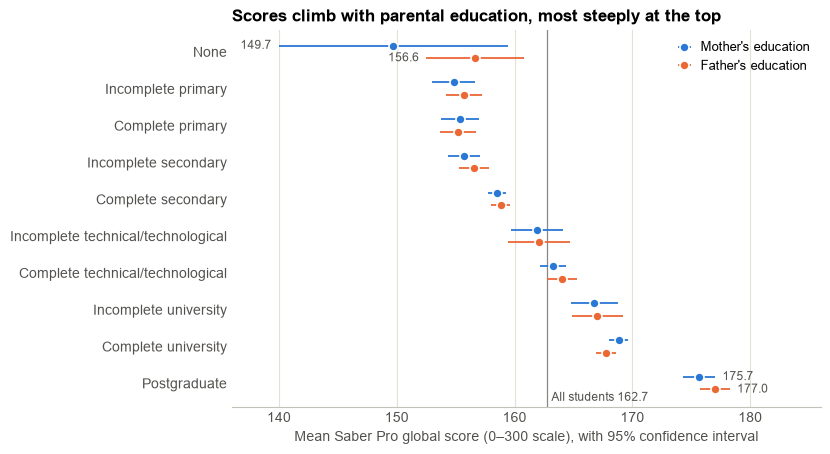

In [10]:
def fig_parent_education(data, title=None):
    fig, ax = plt.subplots(figsize=(7.6, 4.9))
    y = np.arange(len(EDU_ORDER))
    for col, label, color, offset in [("EDU_MOTHER", "Mother's education", WOMEN, -0.17),
                                      ("EDU_FATHER", "Father's education", MEN, 0.17)]:
        t = group_table(data, col).reindex(EDU_ORDER)
        ax.errorbar(t["Mean"], y + offset, xerr=[t["Mean"] - t["95% CI low"], t["95% CI high"] - t["Mean"]],
                    fmt="o", ms=6.5, color=color, mec="white", mew=1.2, ecolor=color, elinewidth=1.3,
                    capsize=0, label=label, zorder=3)
        ax.text(t["95% CI low"].iloc[0] - 0.6, y[0] + offset, f"{t['Mean'].iloc[0]:.1f}",
                va="center", ha="right", fontsize=8.5, color=INK2)
        ax.text(t["95% CI high"].iloc[-1] + 0.6, y[-1] + offset, f"{t['Mean'].iloc[-1]:.1f}",
                va="center", ha="left", fontsize=8.5, color=INK2)
    overall = data["G_SC"].mean()
    ax.axvline(overall, color=MUTED, lw=0.9, zorder=1)
    ax.text(overall + 0.4, len(EDU_ORDER) - 0.45, f"All students {overall:.1f}", fontsize=8.5, color=INK2, va="bottom")
    ax.set_yticks(y)
    ax.set_yticklabels(EDU_ORDER)
    ax.set_ylim(len(EDU_ORDER) - 0.35, -0.6)
    ax.set_xlim(136, 186)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("Mean Saber Pro global score (0–300 scale), with 95% confidence interval")
    ax.legend(loc="upper right", fontsize=9, handletextpad=0.3)
    if title:
        ax.set_title(title)
    return fig

fig = fig_parent_education(df, title="Scores climb with parental education, most steeply at the top")
save(fig, "fig1_parent_education.png")
plt.show()

In [11]:
fg = df.dropna(subset=["FIRST_GEN"])
first, cont = fg.loc[fg["FIRST_GEN"] == 1, "G_SC"], fg.loc[fg["FIRST_GEN"] == 0, "G_SC"]
t_stat, p_val = stats.ttest_ind(first, cont, equal_var=False)
d = cohens_d(first, cont)
lo, hi = d_ci(d, len(first), len(cont))
print(f"First-generation students (neither parent beyond secondary): {len(first):,} ({len(first) / len(fg):.1%} of those with a reported parent)")
print(f"Mean G_SC: first-generation {first.mean():.1f} vs continuing-generation {cont.mean():.1f} "
      f"(gap {first.mean() - cont.mean():.1f} points)")
print(f"Welch t = {t_stat:.2f}, p = {p_val:.1e}; Cohen's d = {d:.2f} [95% CI {lo:.2f}, {hi:.2f}]")

tk = df.dropna(subset=["PAR_EDU_BAND"])
tukey = stats.tukey_hsd(*[g["G_SC"].to_numpy() for _, g in tk.groupby("PAR_EDU_BAND", observed=True)])
print("\nTukey HSD adjusted p-values between parental-education bands:")
display(pd.DataFrame(tukey.pvalue, index=BAND_ORDER, columns=BAND_ORDER))

First-generation students (neither parent beyond secondary): 4,403 (36.8% of those with a reported parent)
Mean G_SC: first-generation 156.3 vs continuing-generation 166.9 (gap -10.7 points)
Welch t = -25.18, p = 1.7e-135; Cohen's d = -0.47 [95% CI -0.51, -0.43]



Tukey HSD adjusted p-values between parental-education bands:


,Primary or less,Secondary,Technical/technological,Some university,University degree,Postgraduate
Primary or less,1.00,0.0455,0,0,0,0
Secondary,0.0455,1.00,5.18e-10,4.03e-10,0,0
Technical/technological,0,5.18e-10,1.00,0.102,0,0
Some university,0,4.03e-10,0.102,1.00,0.376,0
University degree,0,0,0,0.376,1.00,0
Postgraduate,0,0,0,0,0,1.00


**Interpretation.** Parental education clearly influences outcomes. The mean global score barely moves until a parent has finished secondary school (about 155–159 points). After that it climbs steadily, and the largest single step comes at the top: students whose more-educated parent holds a postgraduate degree average **175.3**, against **154.4** for students whose parents have primary schooling or less. That is a gap of **20.9 points, or 0.95 standard deviations**. Fathers' and mothers' education show almost the same gradient (Spearman ρ = 0.27 for each), and each explains about **7.5% of the variance** in the global score (ω² = 0.076 for fathers and 0.074 for mothers, a medium effect). First-generation students (neither parent studied past secondary school), who make up 37% of students with a reported parent, score **10.7 points lower** than their peers (*d* = −0.47). Section 10 shows how much of this gap survives once stratum, income, school type and Saber 11 results are taken into account.

## 7. Q2: Which stratum performs best, and do strata differ?

Colombia classifies homes into six socioeconomic strata (*estratos*), from 1 (lowest) to 6 (highest), for utility pricing and subsidies. Fourteen students with no stratum recorded are left out of this section. We compare the global score across strata with a classic ANOVA, Welch's ANOVA (which allows unequal variances) and the rank-based Kruskal–Wallis test, then use Tukey's HSD to find which pairs of strata differ.

In [12]:
strat = group_table(df, "STRATUM")
strat["% in national top quartile"] = df.groupby("STRATUM", observed=True)["QUARTILE"].apply(lambda q: 100 * (q == 4).mean())
strat["Gap vs stratum 1"] = strat["Mean"] - strat.loc["Stratum 1", "Mean"]
print("Table C. Saber Pro global score by socioeconomic stratum")
display(strat.round(2))
strat.round(2).to_csv(os.path.join(OUT_DIR, "gsc_by_stratum.csv"))
display(compare_groups(df, "STRATUM").to_frame())
rho, p = stats.spearmanr(df["STRATUM_NUM"], df["G_SC"], nan_policy="omit")
s1, s6 = df.loc[df["STRATUM"] == "Stratum 1", "G_SC"], df.loc[df["STRATUM"] == "Stratum 6", "G_SC"]
print(f"Spearman rho (stratum vs G_SC) = {rho:.3f}; Cohen's d, stratum 6 vs 1 = {cohens_d(s6, s1):.2f}")

st = df.dropna(subset=["STRATUM"])
tukey = stats.tukey_hsd(*[g["G_SC"].to_numpy() for _, g in st.groupby("STRATUM", observed=True)])
ci = tukey.confidence_interval(confidence_level=0.95)
pairs = []
for i in range(6):
    for j in range(i + 1, 6):
        pairs.append({"Comparison": f"{STRATUM_ORDER[j]} − {STRATUM_ORDER[i]}",
                      "Mean difference": -tukey.statistic[i, j], "95% CI low": -ci.high[i, j],
                      "95% CI high": -ci.low[i, j], "Adjusted p": tukey.pvalue[i, j]})
pairs = pd.DataFrame(pairs)
print("\nTukey HSD: every pair of strata")
display(tidy(pairs))

spread = st.groupby("STRATUM", observed=True)["G_SC"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()
spread.columns = ["P10", "Q1", "Median", "Q3", "P90"]
spread["% above the all-student mean"] = st.groupby("STRATUM", observed=True)["G_SC"].apply(
    lambda s: 100 * (s > df["G_SC"].mean()).mean())
print("How much the strata overlap")
display(spread.round(1))

Table C. Saber Pro global score by socioeconomic stratum


,n,% of students,Mean,SD,Median,95% CI low,95% CI high,% in national top quartile,Gap vs stratum 1
STRATUM,,,,,,,,,
Stratum 1,1707,13.79,152.39,21.92,152.00,151.35,153.43,31.93,0
Stratum 2,4026,32.52,158.21,22.28,158.00,157.52,158.90,42.55,5.82
Stratum 3,4039,32.62,163.81,21.69,164.00,163.14,164.48,52.98,11.43
Stratum 4,1575,12.72,172.03,21.48,174.00,170.97,173.09,69.08,19.65
Stratum 5,631,5.10,177.47,21.49,179.00,175.79,179.15,77.65,25.09
Stratum 6,403,3.25,181.51,21.88,184.00,179.37,183.65,82.38,29.12


,G_SC by STRATUM
groups,6
n,12381
ANOVA F,286.11
ANOVA p,1.36e-290
Welch F,288.62
Welch df,"5, 2383"
Welch p,6.9e-242
Kruskal-Wallis H,"1,286.81"
Kruskal-Wallis p,4.6e-276
eta^2,0.104


Spearman rho (stratum vs G_SC) = 0.312; Cohen's d, stratum 6 vs 1 = 1.33



Tukey HSD: every pair of strata

,Comparison,Mean difference,95% CI low,95% CI high,Adjusted p
0,Stratum 2 − Stratum 1,5.82,4.02,7.63,3.19e-13
1,Stratum 3 − Stratum 1,11.43,9.62,13.23,3.19e-13
2,Stratum 4 − Stratum 1,19.65,17.47,21.82,3.19e-13
3,Stratum 5 − Stratum 1,25.09,22.18,27.99,3.19e-13
4,Stratum 6 − Stratum 1,29.12,25.67,32.58,3.19e-13
5,Stratum 3 − Stratum 2,5.60,4.21,6.99,3.19e-13
6,Stratum 4 − Stratum 2,13.82,11.97,15.67,3.19e-13
7,Stratum 5 − Stratum 2,19.26,16.59,21.93,3.19e-13
8,Stratum 6 − Stratum 2,23.30,20.04,26.56,3.19e-13
9,Stratum 4 − Stratum 3,8.22,6.37,10.07,3.19e-13


How much the strata overlap


,P10,Q1,Median,Q3,P90,% above the all-student mean
STRATUM,,,,,,
Stratum 1,125.00,138.00,152.00,167.00,181.00,31.90
Stratum 2,129.00,143.00,158.00,174.00,187.00,42.50
Stratum 3,135.00,149.00,164.00,179.00,191.00,53.00
Stratum 4,143.00,158.00,174.00,188.00,198.00,69.10
Stratum 5,149.00,165.50,179.00,192.00,201.00,77.70
Stratum 6,152.20,170.00,184.00,194.50,207.00,82.40


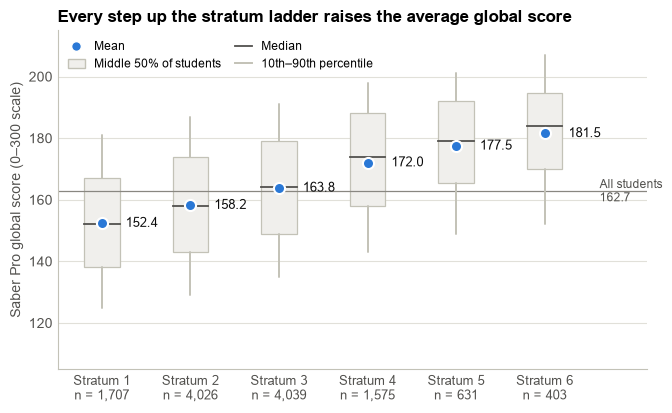

In [13]:
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

def fig_stratum(data, title=None):
    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    labels = []
    for i, s in enumerate(STRATUM_ORDER, start=1):
        v = data.loc[data["STRATUM"] == s, "G_SC"].to_numpy()
        p10, q1, med, q3, p90 = np.percentile(v, [10, 25, 50, 75, 90])
        ax.plot([i, i], [p10, q1], color=AXIS, lw=1.4, solid_capstyle="round")
        ax.plot([i, i], [q3, p90], color=AXIS, lw=1.4, solid_capstyle="round")
        ax.add_patch(Rectangle((i - 0.2, q1), 0.4, q3 - q1, facecolor="#f0efec", edgecolor=AXIS, lw=0.9))
        ax.plot([i - 0.2, i + 0.2], [med, med], color=INK2, lw=1.3)
        ax.plot(i, v.mean(), "o", ms=8, color=BLUE, mec="white", mew=1.5, zorder=4)
        ax.text(i + 0.27, v.mean(), f"{v.mean():.1f}", va="center", fontsize=9, color=INK)
        labels.append(f"{s}\nn = {len(v):,}")
    overall = data["G_SC"].mean()
    ax.axhline(overall, color=MUTED, lw=0.9, zorder=1)
    ax.text(6.62, overall, f"All students\n{overall:.1f}", fontsize=8.5, color=INK2, va="center")
    ax.set_xticks(range(1, 7))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_xlim(0.5, 7.15)
    ax.set_ylim(105, 215)
    ax.set_ylabel("Saber Pro global score (0–300 scale)")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    handles = [Line2D([], [], marker="o", ls="", ms=7, color=BLUE, mec="white", label="Mean"),
               Rectangle((0, 0), 1, 1, facecolor="#f0efec", edgecolor=AXIS, label="Middle 50% of students"),
               Line2D([], [], color=INK2, lw=1.3, label="Median"),
               Line2D([], [], color=AXIS, lw=1.4, label="10th–90th percentile")]
    ax.legend(handles=handles, loc="upper left", fontsize=8.5, ncol=2, handlelength=1.4, columnspacing=1.2)
    if title:
        ax.set_title(title)
    return fig

fig = fig_stratum(df, title="Every step up the stratum ladder raises the average global score")
save(fig, "fig2_stratum.png")
plt.show()

### Which skills carry the stratum gap?

The global score averages five generic modules. Comparing the stratum gradient module by module shows where the gap comes from.

STRATUM,Stratum 1,Stratum 2,Stratum 3,Stratum 4,Stratum 5,Stratum 6,Stratum 6 − 1,eta^2 (stratum),d (6 vs 1)
Mathematics (S11),59.86,62.08,64.34,69.12,72.20,74.67,14.81,0.1,1.33
Critical reading (S11),57.09,59.13,61.48,64.07,65.53,66.01,8.92,0.06,0.92
Citizenship competencies (S11),57.28,59.22,61.30,63.59,64.93,66.67,9.39,0.05,0.96
Biology (S11),60.24,62.10,63.96,67.72,71.07,72.67,12.43,0.08,1.14
English (S11),53.43,57.21,62.38,69.83,77.08,82.38,28.95,0.25,2.74
Quantitative reasoning (Pro),70.53,74.62,78.33,83.23,86.76,88.36,17.84,0.04,0.76
Critical reading (Pro),53.62,58.84,63.86,69.29,71.81,73.76,20.14,0.04,0.73
Citizenship competencies (Pro),50.94,55.96,60.15,67.04,69.30,71.07,20.13,0.04,0.71
English (Pro),50.93,60.94,70.63,80.09,87.10,92.45,41.52,0.18,1.73
Written communication (Pro),49.35,51.17,53.05,59.62,63.76,65.59,16.24,0.02,0.55


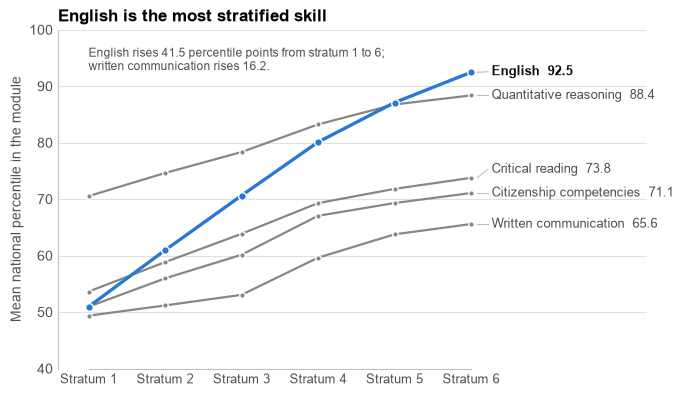

In [14]:
mods = PRO + ["FEP_PRO", "G_SC"]
by_stratum = st.groupby("STRATUM", observed=True)[S11 + mods].mean().T
by_stratum.columns = by_stratum.columns.astype(str)
by_stratum["Stratum 6 − 1"] = by_stratum["Stratum 6"] - by_stratum["Stratum 1"]
by_stratum["eta^2 (stratum)"] = [variance_explained(df[c], df["STRATUM"])[0] for c in by_stratum.index]
by_stratum["d (6 vs 1)"] = [cohens_d(df.loc[df["STRATUM"] == "Stratum 6", c], df.loc[df["STRATUM"] == "Stratum 1", c])
                            for c in by_stratum.index]
by_stratum.index = [f"{NICE[c]} ({'S11' if c.endswith('S11') else 'Pro'})" for c in by_stratum.index]
display(by_stratum.round(2))

def fig_modules_by_stratum(data, title=None):
    means = data.dropna(subset=["STRATUM"]).groupby("STRATUM", observed=True)[PRO].mean()
    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    x = np.arange(1, 7)
    order = sorted(PRO, key=lambda c: means[c].iloc[-1])
    for c in order:
        is_eng = c == "ENG_PRO"
        ax.plot(x, means[c], color=BLUE if is_eng else MUTED, lw=2.4 if is_eng else 1.6,
                marker="o", ms=5.5 if is_eng else 4, mec="white", mew=1, zorder=3 if is_eng else 2)
    # end labels, nudged apart when they would collide
    ends = sorted([(means[c].iloc[-1], c) for c in PRO])
    placed = []
    for value, c in ends:
        pos = value if not placed else max(value, placed[-1] + 4.2)
        placed.append(pos)
        ax.plot([6.08, 6.22], [value, pos], color=AXIS, lw=0.8)
        ax.text(6.27, pos, f"{NICE[c]}  {value:.1f}", va="center", fontsize=9,
                color=INK if c == "ENG_PRO" else INK2, fontweight="bold" if c == "ENG_PRO" else "normal")
    eng = means["ENG_PRO"]
    ax.text(1.0, 97, f"English rises {eng.iloc[-1] - eng.iloc[0]:.1f} percentile points from stratum 1 to 6;\n"
            f"written communication rises {means['WC_PRO'].iloc[-1] - means['WC_PRO'].iloc[0]:.1f}.",
            fontsize=8.5, color=INK2, va="top")
    ax.set_xticks(x)
    ax.set_xticklabels(STRATUM_ORDER, fontsize=9)
    ax.set_xlim(0.6, 8.3)
    ax.set_ylim(40, 100)
    ax.spines["bottom"].set_bounds(1, 6)
    ax.set_ylabel("Mean national percentile in the module")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title)
    return fig

fig = fig_modules_by_stratum(df, title="English is the most stratified skill")
save(fig, "fig3_modules_by_stratum.png")
plt.show()

**Interpretation.** The global score rises at every step of the ladder, from **152.4 in stratum 1 to 181.5 in stratum 6**. Stratum 6 performs best, and the 29.1-point gap from stratum 1 is a very large effect (*d* = 1.33). The differences are real and not driven by a few outliers: the classic ANOVA, Welch's ANOVA and Kruskal–Wallis tests all reject equal means (p < .001), and stratum explains about **10% of the variance** in the global score (ω² = 0.103, a medium-to-large effect). Tukey's HSD separates every pair of strata at p < .001 except the top two (5 vs 6, p = .04). The distributions still overlap heavily: 31.9% of stratum-1 students score above the all-student average, and 17.6% of stratum-6 students score below it. The gap is concentrated in **English**, where the mean national percentile climbs from 50.9 in stratum 1 to 92.5 in stratum 6 (η² = 0.18, about four times the stratum effect on quantitative reasoning or critical reading, η² ≈ 0.04). The same is true at the end of high school, where stratum explains 25% of the variance in Saber 11 English. The gap is smallest in the engineering-specific *Formulation of Engineering Projects* module (η² = 0.02).

## 8. Q3: How does each gender perform on the global assessment?

The global assessment is the Saber Pro global score (`G_SC`). We compare women and men with Welch's *t*-test (unequal variances), the Mann–Whitney *U* test (no normality assumption) and Cohen's *d*, then break the comparison down by module and by stratum.

In [15]:
gender = group_table(df, "GENDER")
women, men = df.loc[df["GENDER"] == "Female", "G_SC"], df.loc[df["GENDER"] == "Male", "G_SC"]
t_stat, p_t = stats.ttest_ind(women, men, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(women, men, alternative="two-sided")
d = cohens_d(women, men)
lo, hi = d_ci(d, len(women), len(men))
gender["% in national top quartile"] = df.groupby("GENDER", observed=True)["QUARTILE"].apply(lambda q: 100 * (q == 4).mean())
gender["% with zero in Written Communication"] = df.groupby("GENDER", observed=True)["WC_PRO"].apply(lambda s: 100 * (s == 0).mean())
print("Table D. Saber Pro global score by gender")
display(gender.round(2))
gender.round(2).to_csv(os.path.join(OUT_DIR, "gsc_by_gender.csv"))
print(f"Difference (women − men): {women.mean() - men.mean():.2f} points")
print(f"Welch t = {t_stat:.2f}, p = {p_t:.1e} | Mann–Whitney U p = {p_u:.1e} | "
      f"Cohen's d = {d:.2f} [95% CI {lo:.2f}, {hi:.2f}]")

no_zero = df[df["WC_PRO"] > 0]
w0, m0 = no_zero.loc[no_zero["FEMALE"] == 1, "G_SC"], no_zero.loc[no_zero["FEMALE"] == 0, "G_SC"]
print(f"Excluding the {int((df['WC_PRO'] == 0).sum())} zero Written Communication scores: "
      f"women {w0.mean():.1f}, men {m0.mean():.1f}, d = {cohens_d(w0, m0):.2f}")

print("\nGlobal score by gender within each stratum")
within = df.pivot_table(index="STRATUM", columns="GENDER", values="G_SC", aggfunc="mean", observed=True)
within.columns = within.columns.astype(str)
within["Women − men"] = within["Female"] - within["Male"]
within["% women"] = df.groupby("STRATUM", observed=True)["FEMALE"].mean() * 100
display(within.round(2))

Table D. Saber Pro global score by gender


,n,% of students,Mean,SD,Median,95% CI low,95% CI high,% in national top quartile,% with zero in Written Communication
GENDER,,,,,,,,,
Female,5036,40.63,161.30,22.33,162.00,160.69,161.92,48.27,1.71
Male,7359,59.37,163.70,23.58,164.00,163.16,164.23,52.74,3.02


Difference (women − men): -2.39 points
Welch t = -5.72, p = 1.1e-08 | Mann–Whitney U p = 1.7e-08 | Cohen's d = -0.10 [95% CI -0.14, -0.07]
Excluding the 308 zero Written Communication scores: women 162.0, men 164.8, d = -0.12

Global score by gender within each stratum


GENDER,Female,Male,Women − men,% women
STRATUM,,,,
Stratum 1,151.69,152.88,-1.19,41.24
Stratum 2,157.32,158.83,-1.51,40.78
Stratum 3,162.36,164.85,-2.49,41.59
Stratum 4,170.62,172.99,-2.37,40.57
Stratum 5,175.47,178.65,-3.18,37.08
Stratum 6,179.00,182.72,-3.72,32.51


Gender gaps by subject (positive = women score higher)


,Test,Variable,Subject,Women,Men,Women − men,Cohen's d,d 95% CI low,d 95% CI high,Welch p
0,Saber 11,MAT_S11,Mathematics,61.94,65.96,-4.01,-0.343,-0.379,-0.307,2.07e-79
1,Saber 11,CR_S11,Critical reading,60.91,60.70,0.204,0.02,-0.015,0.056,0.264
2,Saber 11,CC_S11,Citizenship competencies,59.97,61.22,-1.25,-0.124,-0.16,-0.088,5.97e-12
3,Saber 11,BIO_S11,Biology,62.28,65.11,-2.83,-0.256,-0.292,-0.22,2.48e-45
4,Saber 11,ENG_S11,English,61.45,62.04,-0.586,-0.041,-0.077,-0.005,0.0235
5,Saber Pro,QR_PRO,Quantitative reasoning,71.91,81.19,-9.29,-0.418,-0.454,-0.382,6.29e-107
6,Saber Pro,CR_PRO,Critical reading,61.36,62.80,-1.44,-0.052,-0.088,-0.016,0.00425
7,Saber Pro,CC_PRO,Citizenship competencies,58.60,59.61,-1.01,-0.035,-0.071,0.001,0.0538
8,Saber Pro,ENG_PRO,English,66.54,68.16,-1.62,-0.063,-0.099,-0.028,0.000466
9,Saber Pro,WC_PRO,Written communication,56.66,51.71,4.95,0.166,0.13,0.201,9.16e-20


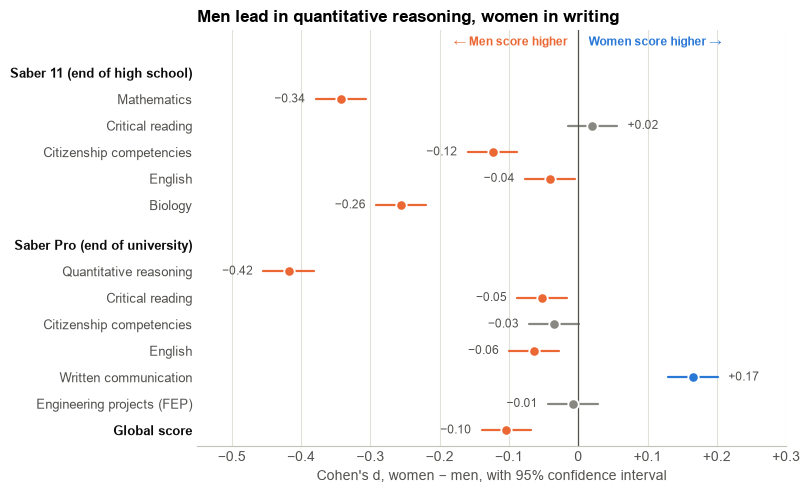

In [16]:
rows = []
for c in S11 + PRO + ["FEP_PRO", "G_SC"]:
    w, m = df.loc[df["FEMALE"] == 1, c], df.loc[df["FEMALE"] == 0, c]
    d = cohens_d(w, m)
    lo, hi = d_ci(d, len(w), len(m))
    rows.append({"Test": "Saber 11" if c.endswith("S11") else "Saber Pro", "Variable": c, "Subject": NICE[c],
                 "Women": w.mean(), "Men": m.mean(), "Women − men": w.mean() - m.mean(),
                 "Cohen's d": d, "d 95% CI low": lo, "d 95% CI high": hi,
                 "Welch p": stats.ttest_ind(w, m, equal_var=False).pvalue})
gaps = pd.DataFrame(rows)
print("Gender gaps by subject (positive = women score higher)")
display(tidy(gaps, 3))
tidy(gaps, 3).to_csv(os.path.join(OUT_DIR, "gender_gaps_by_subject.csv"), index=False)

def fig_gender_gaps(gaps, title=None):
    blocks = [("Saber 11 (end of high school)", ["MAT_S11", "CR_S11", "CC_S11", "ENG_S11", "BIO_S11"]),
              ("Saber Pro (end of university)", ["QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO", "FEP_PRO", "G_SC"])]
    g = gaps.set_index("Variable")
    fig, ax = plt.subplots(figsize=(7.6, 5.4))
    ticks, labels, heads, y = [], [], [], 0.0
    for heading, block in blocks:
        ticks.append(y); labels.append(heading); heads.append(y)
        y += 1
        for c in block:
            r = g.loc[c]
            d_value, low, high = r["Cohen's d"], r["d 95% CI low"], r["d 95% CI high"]
            significant = low > 0 or high < 0
            color = (WOMEN if d_value > 0 else MEN) if significant else MUTED
            ax.plot([low, high], [y, y], color=color, lw=1.6, solid_capstyle="round")
            ax.plot(d_value, y, "o", ms=7.5, color=color, mec="white", mew=1.3, zorder=3)
            if d_value < 0:
                ax.text(low - 0.015, y, signed(d_value), va="center", ha="right", fontsize=8.5, color=INK2)
            else:
                ax.text(high + 0.015, y, signed(d_value), va="center", ha="left", fontsize=8.5, color=INK2)
            ticks.append(y); labels.append(NICE[c])
            y += 1
        y += 0.5
    ax.axvline(0, color=INK2, lw=0.9)
    ax.set_yticks(ticks)
    ax.set_yticklabels(labels, fontsize=9)
    for tick_y, label in zip(ticks, ax.get_yticklabels()):
        if tick_y in heads or label.get_text() == "Global score":
            label.set_fontweight("bold")
            label.set_color(INK)
    ax.set_ylim(y - 0.9, -1.6)
    ax.set_xlim(-0.55, 0.3)
    ax.spines["left"].set_visible(False)
    xt = np.round(np.arange(-0.5, 0.31, 0.1), 1)
    ax.set_xticks(xt)
    ax.set_xticklabels([signed(v, 1) if v != 0 else "0" for v in xt])
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.set_xlabel("Cohen's d, women − men, with 95% confidence interval")
    ax.text(-0.015, -1.15, "← Men score higher", ha="right", va="center", fontsize=8.5, color=MEN, fontweight="bold")
    ax.text(0.015, -1.15, "Women score higher →", ha="left", va="center", fontsize=8.5, color=WOMEN, fontweight="bold")
    if title:
        ax.set_title(title)
    return fig

fig = fig_gender_gaps(gaps, title="Men lead in quantitative reasoning, women in writing")
save(fig, "fig4_gender_gaps.png")
plt.show()

In [17]:
print("Do the gaps remain for students who entered with the same Saber 11 scores?")
for outcome, prior in [("QR_PRO", ["MAT_S11"]), ("WC_PRO", ["CR_S11"]), ("G_SC", S11)]:
    table, fit = ols(df, outcome, prior + ["FEMALE"])
    r = table.loc["FEMALE"]
    print(f"  {outcome} controlling for {', '.join(prior)}: women − men = {r['coef']:+.2f} "
          f"[95% CI {r['95% CI low']:+.2f}, {r['95% CI high']:+.2f}], p = {r['p']:.3f}")

print("\nWomen − men gap in Quantitative Reasoning and Written Communication within each program")
prog_gap = df.groupby("PROGRAM_GROUP")[["FEMALE", "QR_PRO", "WC_PRO"]].apply(lambda g: pd.Series({
    "n": len(g), "% women": 100 * g["FEMALE"].mean(),
    "QR gap (pctl pts)": g.loc[g["FEMALE"] == 1, "QR_PRO"].mean() - g.loc[g["FEMALE"] == 0, "QR_PRO"].mean(),
    "WC gap (pctl pts)": g.loc[g["FEMALE"] == 1, "WC_PRO"].mean() - g.loc[g["FEMALE"] == 0, "WC_PRO"].mean()}))
prog_gap["n"] = prog_gap["n"].astype(int)
display(prog_gap.round(1))

Do the gaps remain for students who entered with the same Saber 11 scores?


  QR_PRO controlling for MAT_S11: women − men = -4.70 [95% CI -5.35, -4.04], p = 0.000
  WC_PRO controlling for CR_S11: women − men = +4.81 [95% CI +3.77, +5.85], p = 0.000
  G_SC controlling for MAT_S11, CR_S11, CC_S11, BIO_S11, ENG_S11: women − men = +0.38 [95% CI -0.14, +0.91], p = 0.151

Women − men gap in Quantitative Reasoning and Written Communication within each program


,n,% women,QR gap (pctl pts),WC gap (pctl pts)
PROGRAM_GROUP,,,,
Chemical Engineering,1000,54.50,-6.70,6.50
Civil Engineering,3310,35.90,-9.50,3.60
Electric Engineering,278,21.90,-6.30,1.80
Electronic Engineering,848,19.60,-8.10,5.80
Industrial Engineering,5315,51.90,-8.70,3.40
Mechanical Engineering,1133,12.00,-3.80,4.10
Other Programs (15),511,35.00,-1.70,9.70


**Interpretation.** On the global assessment, women and men perform almost identically. Women average **161.3** and men **163.7**, a gap of 2.4 points on a 300-point scale (*d* = −0.10, a negligible effect). The gap is statistically detectable only because the sample is large. It is the same size in every stratum (1 to 4 points) and disappears entirely for students who entered with the same Saber 11 scores. The near-zero average hides two opposite gaps, however. Men lead in **quantitative reasoning** by 9.3 percentile points (*d* = −0.42), a larger gap than in high-school mathematics (*d* = −0.34), and women still trail by 4.7 points when compared with men who had the same Saber 11 mathematics score. Women lead in **written communication** by 5.0 points (*d* = +0.17), partly because men are almost twice as likely to score zero on the essay (3.0% vs 1.7%). Both patterns appear in every engineering program.

## 9. Other attributes: what else is associated with the global score?

To compare attributes on one scale, ω² is computed for each attribute: the share of variance in the global score each attribute explains on its own (bias-corrected η²). For the five Saber 11 scores, which are continuous, the comparable figure is the adjusted R² of a regression of `G_SC` on all five.

Share of variance in the global score explained by each attribute on its own


,Attribute,Column,Levels,n,eta^2,omega^2,ANOVA p
0,Saber 11 scores (five subjects),S11 (regression),NaN,12395,0.608,0.608,NaN
1,University attended (134 institutions),UNIVERSITY,134.00,12395,0.396,0.389,0
2,Institution's socioeconomic level,SEL_IHE,4.00,12395,0.145,0.144,0
3,Family income,REVENUE,7.00,12116,0.112,0.112,8.94e-308
4,Socioeconomic stratum,STRATUM,6.00,12381,0.104,0.103,1.36e-290
5,Student socioeconomic level index,SEL,4.00,12395,0.0775,0.0773,1.59e-216
6,Parental education (more-educated parent),PAR_EDU_BAND,6.00,11950,0.0768,0.0764,3.54e-204
7,SISBEN classification,SISBEN,5.00,12374,0.0723,0.0719,1.67e-199
8,Public vs private high school,SCHOOL_NAT,2.00,12395,0.064,0.0639,3.55e-180
9,Academic program (21),PROGRAM,21.00,12395,0.0582,0.0567,2.25e-144


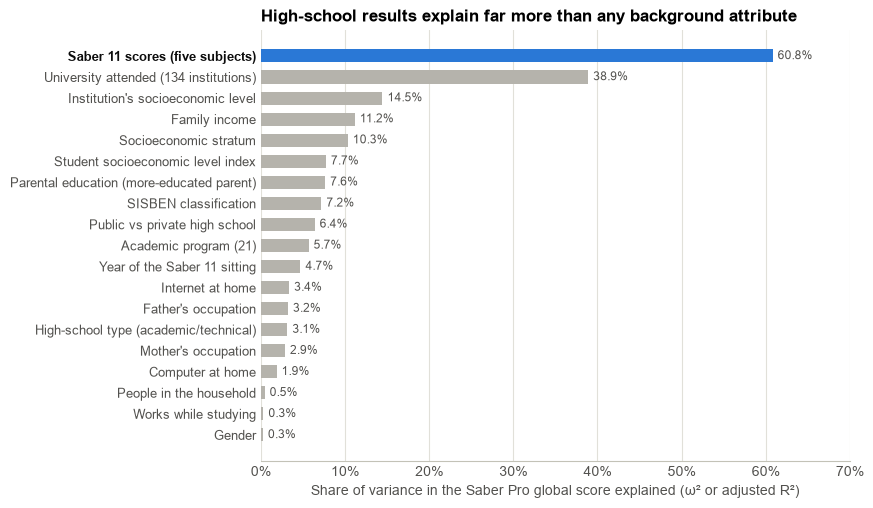

In [18]:
attribute_names = {
    "UNIVERSITY": "University attended (134 institutions)", "SEL_IHE": "Institution's socioeconomic level",
    "REVENUE": "Family income", "STRATUM": "Socioeconomic stratum", "SEL": "Student socioeconomic level index",
    "PAR_EDU_BAND": "Parental education (more-educated parent)", "SISBEN": "SISBEN classification",
    "SCHOOL_NAT": "Public vs private high school", "PROGRAM": "Academic program (21)",
    "S11_YEAR": "Year of the Saber 11 sitting", "INTERNET": "Internet at home",
    "OCC_FATHER": "Father's occupation", "SCHOOL_TYPE": "High-school type (academic/technical)",
    "OCC_MOTHER": "Mother's occupation", "COMPUTER": "Computer at home", "PEOPLE_HOUSE": "People in the household",
    "JOB": "Works while studying", "GENDER": "Gender"}
rows = []
for col, name in attribute_names.items():
    d = df[[col, "G_SC"]].dropna()
    eta2, omega2 = variance_explained(d["G_SC"], d[col])
    F, p = stats.f_oneway(*[g["G_SC"].to_numpy() for _, g in d.groupby(col, observed=True)])
    rows.append({"Attribute": name, "Column": col, "Levels": d[col].nunique(), "n": len(d),
                 "eta^2": eta2, "omega^2": omega2, "ANOVA p": p})
s11_table, s11_fit = ols(df, "G_SC", S11)
rows.append({"Attribute": "Saber 11 scores (five subjects)", "Column": "S11 (regression)", "Levels": np.nan,
             "n": s11_fit["n"], "eta^2": s11_fit["R2"], "omega^2": s11_fit["adj. R2"], "ANOVA p": np.nan})
league = pd.DataFrame(rows).sort_values("omega^2", ascending=False).reset_index(drop=True)
print("Share of variance in the global score explained by each attribute on its own")
display(tidy(league, 4))
tidy(league, 4).to_csv(os.path.join(OUT_DIR, "variance_explained_by_attribute.csv"), index=False)

from matplotlib.ticker import PercentFormatter

def fig_variance_explained(league, title=None):
    t = league.sort_values("omega^2")
    fig, ax = plt.subplots(figsize=(7.6, 5.6))
    y = np.arange(len(t))
    colors = [BLUE if c == "S11 (regression)" else "#b5b3ac" for c in t["Column"]]
    ax.barh(y, t["omega^2"], height=0.62, color=colors, edgecolor="white", linewidth=0)
    for yi, v in zip(y, t["omega^2"]):
        ax.text(v + 0.006, yi, f"{100 * v:.1f}%", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y)
    ax.set_yticklabels(t["Attribute"], fontsize=9)
    for label in ax.get_yticklabels():
        if label.get_text().startswith("Saber 11"):
            label.set_fontweight("bold")
            label.set_color(INK)
    ax.set_xlim(0, 0.7)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("Share of variance in the Saber Pro global score explained (ω² or adjusted R²)")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    if title:
        ax.set_title(title)
    return fig

fig = fig_variance_explained(league, title="High-school results explain far more than any background attribute")
save(fig, "fig5_variance_explained.png")
plt.show()

### 9.1 Family income, SISBEN and type of high school

In [19]:
for col in ["REVENUE", "SISBEN", "SCHOOL_NAT", "SCHOOL_TYPE", "INTERNET", "COMPUTER", "JOB"]:
    print(f"\nSaber Pro global score by {col}")
    display(group_table(df, col).round(2))
display(pd.concat([compare_groups(df, c) for c in ["REVENUE", "SISBEN", "SCHOOL_TYPE"]], axis=1))
pub, priv = df.loc[df["SCHOOL_NAT"] == "Public", "G_SC"], df.loc[df["SCHOOL_NAT"] == "Private", "G_SC"]
t_stat, p_val = stats.ttest_ind(priv, pub, equal_var=False)
print(f"Private − public high school: {priv.mean() - pub.mean():.1f} points; Welch t = {t_stat:.2f}, "
      f"p = {p_val:.1e}; d = {cohens_d(priv, pub):.2f}")
print("\nParental education by stratum (% of each stratum)")
display(pd.crosstab(df["PAR_EDU_BAND"], df["STRATUM"], normalize="columns").mul(100).round(1))
rho, _ = stats.spearmanr(df["STRATUM_NUM"], df["PAR_EDU_RANK"], nan_policy="omit")
print(f"Spearman rho, stratum vs parental education: {rho:.2f}; share of students from public schools in "
      f"stratum 1: {100 * (df.loc[df['STRATUM'] == 'Stratum 1', 'SCHOOL_NAT'] == 'Public').mean():.0f}%, "
      f"stratum 6: {100 * (df.loc[df['STRATUM'] == 'Stratum 6', 'SCHOOL_NAT'] == 'Public').mean():.0f}%")


Saber Pro global score by REVENUE


,n,% of students,Mean,SD,Median,95% CI low,95% CI high
REVENUE,,,,,,,
<1 MMW,1036,8.55,153.30,22.02,153.00,151.95,154.64
1-2 MMW,3867,31.92,156.80,22.04,157.00,156.11,157.50
2-3 MMW,2782,22.96,160.95,21.64,162.00,160.14,161.75
3-5 MMW,2235,18.45,165.33,22.07,167.00,164.42,166.25
5-7 MMW,971,8.01,170.92,21.76,173.00,169.55,172.29
7-10 MMW,508,4.19,176.19,19.98,178.00,174.45,177.93
10+ MMW,717,5.92,183.69,20.73,185.00,182.17,185.21



Saber Pro global score by SISBEN


,n,% of students,Mean,SD,Median,95% CI low,95% CI high
SISBEN,,,,,,,
Level 1,2056,16.62,152.69,21.66,152.00,151.75,153.63
Level 2,2117,17.11,155.94,22.25,156.00,154.99,156.89
Level 3,582,4.70,160.97,21.65,161.00,159.21,162.73
Other level,96,0.78,166.05,22.51,167.00,161.49,170.61
Not classified,7523,60.80,167.48,22.48,169.00,166.97,167.99



Saber Pro global score by SCHOOL_NAT


,n,% of students,Mean,SD,Median,95% CI low,95% CI high
SCHOOL_NAT,,,,,,,
Public,5840,47.12,156.53,21.84,157.00,155.97,157.09
Private,6555,52.88,168.24,22.81,170.00,167.69,168.79


... (8 outputs left out)

,G_SC by REVENUE,G_SC by SISBEN,G_SC by SCHOOL_TYPE
groups,7,5,3
n,12116,12374,12390
ANOVA F,254.61,240.82,202.43
ANOVA p,8.94e-308,1.67e-199,3.1e-87
Welch F,269.85,244.37,209.13
Welch df,"6, 3006","4, 635","2, 2842"
Welch p,7.75e-277,6.14e-127,1.85e-85
Kruskal-Wallis H,"1,334.78",900.68,405.25
Kruskal-Wallis p,3.2e-285,1.19e-193,1e-88
eta^2,0.112,0.0723,0.0317


Private − public high school: 11.7 points; Welch t = 29.18, p = 5.2e-181; d = 0.52

Parental education by stratum (% of each stratum)


STRATUM,Stratum 1,Stratum 2,Stratum 3,Stratum 4,Stratum 5,Stratum 6
PAR_EDU_BAND,,,,,,
Primary or less,20.70,9.10,4.30,3.50,1.80,0
Secondary,46.00,41.90,24.00,9.00,4.90,3.00
Technical/technological,13.30,16.50,16.90,8.50,4.90,2.50
Some university,2.10,3.50,5.10,3.80,3.20,1.80
University degree,15.00,23.00,36.80,49.20,50.80,47.10
Postgraduate,2.90,6.10,13.00,25.90,34.50,45.60


Spearman rho, stratum vs parental education: 0.47; share of students from public schools in stratum 1: 87%, stratum 6: 0%


### 9.2 From high school to university

How strongly do Saber 11 results predict Saber Pro results, and do students change rank between the two exams? "Value added" here is each student's global score minus the score predicted from their five Saber 11 scores. A positive group average means the group finished higher than its high-school results predicted.

In [20]:
corr = df[S11 + PRO + ["FEP_PRO", "G_SC"]].corr().loc[S11, PRO + ["FEP_PRO", "G_SC"]]
corr.index = [NICE[c] + " (S11)" for c in corr.index]
corr.columns = [NICE[c] for c in corr.columns]
print("Pearson correlations between Saber 11 scores (rows) and Saber Pro results (columns)")
display(corr.round(2))
print(f"Saber 11 scores explain R² = {s11_fit['R2']:.3f} of the variance in the global score")
display(tidy(s11_table, 3))

coef = s11_table["coef"].to_numpy()
df["PREDICTED_G_SC"] = coef[0] + df[S11].to_numpy() @ coef[1:]
df["VALUE_ADDED"] = df["G_SC"] - df["PREDICTED_G_SC"]

df["S11_QUARTILE"] = pd.qcut(df["S11_AVG"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
df["G_SC_QUARTILE"] = pd.qcut(df["G_SC"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
print("\nRank persistence: where students from each Saber 11 quartile finish on Saber Pro (row %)")
display(pd.crosstab(df["S11_QUARTILE"], df["G_SC_QUARTILE"], normalize="index").mul(100).round(1))

Pearson correlations between Saber 11 scores (rows) and Saber Pro results (columns)


,Quantitative reasoning,Critical reading,Citizenship competencies,English,Written communication,Engineering projects (FEP),Global score
Mathematics (S11),0.62,0.52,0.46,0.55,0.21,0.26,0.64
Critical reading (S11),0.52,0.59,0.52,0.55,0.23,0.29,0.65
Citizenship competencies (S11),0.5,0.57,0.52,0.51,0.22,0.29,0.63
Biology (S11),0.6,0.56,0.5,0.56,0.22,0.29,0.67
English (S11),0.45,0.5,0.43,0.74,0.26,0.25,0.66


Saber 11 scores explain R² = 0.608 of the variance in the global score


,coef,SE (HC3),t,p,95% CI low,95% CI high
Intercept,47.85,0.91,52.60,0,46.07,49.63
MAT_S11,0.287,0.018,15.72,3.6e-55,0.251,0.322
CR_S11,0.4,0.022,18.43,7.38e-75,0.357,0.442
CC_S11,0.341,0.02,16.66,1.15e-61,0.301,0.381
BIO_S11,0.347,0.021,16.26,7.19e-59,0.305,0.389
ENG_S11,0.473,0.013,37.72,7.88e-295,0.448,0.497



Rank persistence: where students from each Saber 11 quartile finish on Saber Pro (row %)


G_SC_QUARTILE,Q1 (lowest),Q2,Q3,Q4 (highest)
S11_QUARTILE,,,,
Q1 (lowest),69.80,25.00,4.80,0.4
Q2,25.00,42.10,28.30,4.60
Q3,7.40,24.60,43.20,24.80
Q4 (highest),1.80,5.50,23.10,69.60


### 9.3 Programs, institutions and time to degree

In [21]:
programs = df.groupby("PROGRAM_GROUP").agg(
    n=("G_SC", "size"), pct_women=("FEMALE", "mean"), pct_first_gen=("FIRST_GEN", "mean"),
    mean_stratum=("STRATUM_NUM", "mean"), S11_average=("S11_AVG", "mean"), G_SC=("G_SC", "mean"),
    value_added=("VALUE_ADDED", "mean"), QR_pctl=("QR_PRO", "mean"), English_pctl=("ENG_PRO", "mean"),
    WC_pctl=("WC_PRO", "mean")).sort_values("n", ascending=False)
programs[["pct_women", "pct_first_gen"]] *= 100
programs = programs.rename(columns={"pct_women": "% women", "pct_first_gen": "% first-generation",
                                    "mean_stratum": "Mean stratum", "S11_average": "Saber 11 average",
                                    "G_SC": "Mean G_SC", "value_added": "Value added", "QR_pctl": "QR pctl",
                                    "English_pctl": "English pctl", "WC_pctl": "WC pctl"})
print("Table E. Results by academic program (the 15 smallest programs grouped)")
display(programs.round(1))
programs.round(2).to_csv(os.path.join(OUT_DIR, "programs.csv"))

institutions = df.groupby("SEL_IHE").agg(
    institutions=("UNIVERSITY", "nunique"), n=("G_SC", "size"), mean_stratum=("STRATUM_NUM", "mean"),
    S11_average=("S11_AVG", "mean"), G_SC=("G_SC", "mean"), value_added=("VALUE_ADDED", "mean"))
print("Results by the socioeconomic level of the institution (SEL_IHE, 1 = lowest)")
display(institutions.round(1))

cohorts = df.groupby("S11_YEAR").agg(n=("G_SC", "size"), S11_average=("S11_AVG", "mean"),
                                     mean_stratum=("STRATUM_NUM", "mean"), G_SC=("G_SC", "mean"),
                                     value_added=("VALUE_ADDED", "mean"))
print("Results by year of the Saber 11 sitting (all students sat Saber Pro in 2018)")
display(cohorts.round(1))

Table E. Results by academic program (the 15 smallest programs grouped)


,n,% women,% first-generation,Mean stratum,Saber 11 average,Mean G_SC,Value added,QR pctl,English pctl,WC pctl
PROGRAM_GROUP,,,,,,,,,,
Industrial Engineering,5315,51.90,38.00,2.70,60.50,159.10,-0.5,72.10,64.70,54.20
Civil Engineering,3310,35.90,36.00,2.70,61.40,161.10,0.2,78.80,63.80,51.30
Mechanical Engineering,1133,12.00,35.80,2.80,64.80,166.00,-1.20,82.70,72.30,50.50
Chemical Engineering,1000,54.50,27.00,2.90,68.00,176.70,3.30,86.90,82.50,64.00
Electronic Engineering,848,19.60,38.50,2.60,65.10,166.90,-0.9,82.10,73.00,51.20
Other Programs (15),511,35.00,49.60,2.60,62.30,163.40,0.8,79.20,66.70,53.50
Electric Engineering,278,21.90,37.90,2.80,68.00,174.00,1.00,88.70,76.10,57.80


Results by the socioeconomic level of the institution (SEL_IHE, 1 = lowest)


,institutions,n,mean_stratum,S11_average,G_SC,value_added
SEL_IHE,,,,,,
1.00,22,1137,1.90,59.20,153.10,-3.40
2.00,92,7736,2.50,60.30,158.30,-0.5
3.00,8,833,2.90,61.80,164.80,2.90
4.00,12,2689,3.70,69.60,178.80,2.10


Results by year of the Saber 11 sitting (all students sat Saber Pro in 2018)


,n,S11_average,mean_stratum,G_SC,value_added
S11_YEAR,,,,,
2012,4263,60.30,2.60,158.10,-0.8
2013,6836,62.50,2.70,163.10,0
2014,1296,67.70,3.40,175.80,2.60


## 10. How much does background matter once high-school results are known?

Stratum, income, parental education and school type are entangled (section 9.1), and all of them are linked to Saber 11 results. To separate them, we fit nested OLS models on the same 11,695 students with complete data:

* **M1**: parental education only
* **M2**: + gender, stratum, family income and public/private school
* **M3**: + the five Saber 11 scores
* **M4**: + academic program

Standard errors are heteroskedasticity-robust (HC3). Reference groups: parent with primary schooling or less, men, stratum 1, income below one minimum wage, public school, Industrial Engineering.

In [22]:
model_cols = ["PAR_EDU_BAND", "FEMALE", "STRATUM", "REVENUE", "SCHOOL_NAT"] + S11 + ["PROGRAM_GROUP"]
cc = df.dropna(subset=model_cols + ["G_SC"]).copy()
refs = {"PAR_EDU_BAND": "Primary or less", "STRATUM": "Stratum 1", "REVENUE": "<1 MMW",
        "SCHOOL_NAT": "Public", "PROGRAM_GROUP": "Industrial Engineering"}
background = ["PAR_EDU_BAND", "FEMALE", "STRATUM", "REVENUE", "SCHOOL_NAT"]
specs = {"M1": ["PAR_EDU_BAND"], "M2": background, "M3": background + S11, "M4": background + S11 + ["PROGRAM_GROUP"]}
models = {name: ols(cc, "G_SC", cols, {k: v for k, v in refs.items() if k in cols}) for name, cols in specs.items()}

key_terms = ["PAR_EDU_BAND: Secondary", "PAR_EDU_BAND: Technical/technological", "PAR_EDU_BAND: Some university",
             "PAR_EDU_BAND: University degree", "PAR_EDU_BAND: Postgraduate", "FEMALE", "STRATUM: Stratum 3",
             "STRATUM: Stratum 6", "REVENUE: 10+ MMW", "SCHOOL_NAT: Private"] + S11

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

compare = pd.DataFrame("", index=key_terms + ["R²", "Adjusted R²", "n"], columns=list(models))
for name, (table, fit) in models.items():
    for term in key_terms:
        if term in table.index:
            r = table.loc[term]
            compare.loc[term, name] = f"{r['coef']:.2f}{stars(r['p'])} ({r['SE (HC3)']:.2f})"
    compare.loc["R²", name] = f"{fit['R2']:.3f}"
    compare.loc["Adjusted R²", name] = f"{fit['adj. R2']:.3f}"
    compare.loc["n", name] = f"{fit['n']:,}"
print("Table F. OLS models of the Saber Pro global score: coefficient (robust SE); * p<.05 ** p<.01 *** p<.001")
display(compare)
compare.to_csv(os.path.join(OUT_DIR, "regression_models.csv"))

print("Unique contribution of each background block (drop in R² when the block is removed)")
blocks = {"Parental education": "PAR_EDU_BAND", "Stratum": "STRATUM", "Family income": "REVENUE",
          "Public/private school": "SCHOOL_NAT", "Gender": "FEMALE"}
unique = {}
for model_name in ["M2", "M3"]:
    full_r2 = models[model_name][1]["R2"]
    for label, col in blocks.items():
        cols = [c for c in specs[model_name] if c != col]
        _, fit = ols(cc, "G_SC", cols, {k: v for k, v in refs.items() if k in cols})
        unique.setdefault(label, {})[f"ΔR² in {model_name}"] = full_r2 - fit["R2"]
display(pd.DataFrame(unique).T.round(4))
for name in ["M1", "M2", "M3", "M4"]:
    print(f"\n{name}: R² = {models[name][1]['R2']:.3f}")
    display(tidy(models[name][0], 3))

Table F. OLS models of the Saber Pro global score: coefficient (robust SE); * p<.05 ** p<.01 *** p<.001


,M1,M2,M3,M4
PAR_EDU_BAND: Secondary,2.66** (0.82),1.42 (0.81),0.21 (0.54),0.26 (0.53)
PAR_EDU_BAND: Technical/technological,6.95*** (0.91),3.76*** (0.91),0.20 (0.60),0.25 (0.60)
PAR_EDU_BAND: Some university,10.33*** (1.27),5.22*** (1.26),0.33 (0.89),0.37 (0.88)
PAR_EDU_BAND: University degree,12.03*** (0.83),4.20*** (0.86),0.26 (0.57),0.32 (0.57)
PAR_EDU_BAND: Postgraduate,21.34*** (0.93),9.33*** (1.00),1.26 (0.67),1.28 (0.67)
FEMALE,,-2.13*** (0.40),0.34 (0.27),0.10 (0.28)
STRATUM: Stratum 3,,5.88*** (0.75),1.10* (0.50),0.98* (0.50)
STRATUM: Stratum 6,,12.33*** (1.47),-0.23 (1.10),0.09 (1.10)
REVENUE: 10+ MMW,,13.13*** (1.38),1.13 (0.96),1.09 (0.96)
SCHOOL_NAT: Private,,3.76*** (0.49),0.40 (0.33),0.32 (0.33)


Unique contribution of each background block (drop in R² when the block is removed)


,ΔR² in M2,ΔR² in M3
Parental education,0.0091,0.0002
Stratum,0.0104,0.0003
Family income,0.01,0.0003
Public/private school,0.0044,0
Gender,0.002,0



M1: R² = 0.077


,coef,SE (HC3),t,p,95% CI low,95% CI high
Intercept,154.11,0.736,209.50,0,152.67,155.55
PAR_EDU_BAND: Secondary,2.66,0.824,3.22,0.00127,1.04,4.27
PAR_EDU_BAND: Technical/technological,6.95,0.907,7.67,1.89e-14,5.18,8.73
PAR_EDU_BAND: Some university,10.33,1.27,8.14,4.37e-16,7.84,12.81
PAR_EDU_BAND: University degree,12.03,0.826,14.57,1.09e-47,10.41,13.65
PAR_EDU_BAND: Postgraduate,21.34,0.933,22.88,2.44e-113,19.51,23.16


... (2 outputs left out)


M3: R² = 0.615


,coef,SE (HC3),t,p,95% CI low,95% CI high
Intercept,46.13,1.13,40.86,0,43.92,48.34
PAR_EDU_BAND: Secondary,0.209,0.537,0.389,0.697,-0.844,1.26
PAR_EDU_BAND: Technical/technological,0.2,0.604,0.331,0.741,-0.984,1.38
PAR_EDU_BAND: Some university,0.335,0.886,0.378,0.706,-1.40,2.07
PAR_EDU_BAND: University degree,0.258,0.568,0.455,0.649,-0.855,1.37
PAR_EDU_BAND: Postgraduate,1.26,0.67,1.88,0.0597,-0.052,2.58
FEMALE,0.339,0.274,1.24,0.215,-0.197,0.876
STRATUM: Stratum 2,1.07,0.461,2.32,0.0203,0.166,1.97
STRATUM: Stratum 3,1.10,0.497,2.21,0.0272,0.124,2.07
STRATUM: Stratum 4,1.13,0.634,1.78,0.0753,-0.115,2.37



M4: R² = 0.617


,coef,SE (HC3),t,p,95% CI low,95% CI high
Intercept,47.09,1.15,40.90,0,44.83,49.34
PAR_EDU_BAND: Secondary,0.258,0.534,0.483,0.629,-0.789,1.30
PAR_EDU_BAND: Technical/technological,0.246,0.601,0.409,0.683,-0.933,1.43
PAR_EDU_BAND: Some university,0.367,0.885,0.414,0.679,-1.37,2.10
PAR_EDU_BAND: University degree,0.316,0.566,0.559,0.576,-0.793,1.42
PAR_EDU_BAND: Postgraduate,1.28,0.668,1.91,0.0558,-0.032,2.59
FEMALE,0.102,0.285,0.358,0.72,-0.456,0.66
STRATUM: Stratum 2,1.02,0.46,2.22,0.0267,0.117,1.92
STRATUM: Stratum 3,0.976,0.497,1.96,0.0498,0.001,1.95
STRATUM: Stratum 4,1.13,0.635,1.78,0.0744,-0.112,2.38


Gaps in Saber Pro global score points (same 11,695 students)


,Contrast,Raw gap,Adjusted for background,background CI low,background CI high,Adjusted for background + Saber 11,background + Saber 11 CI low,background + Saber 11 CI high
0,Parent with postgraduate degree vs primary or less,21.34,9.33,7.37,11.29,1.26,-0.05,2.58
1,Stratum 6 vs stratum 1,29.87,12.33,9.45,15.21,-0.23,-2.37,1.92
2,Family income 10+ vs under 1 minimum wage,30.33,13.13,10.44,15.83,1.13,-0.76,3.01
3,Private vs public high school,11.78,3.76,2.80,4.73,0.4,-0.24,1.04
4,Women vs men,-2.47,-2.13,-2.92,-1.35,0.34,-0.2,0.88


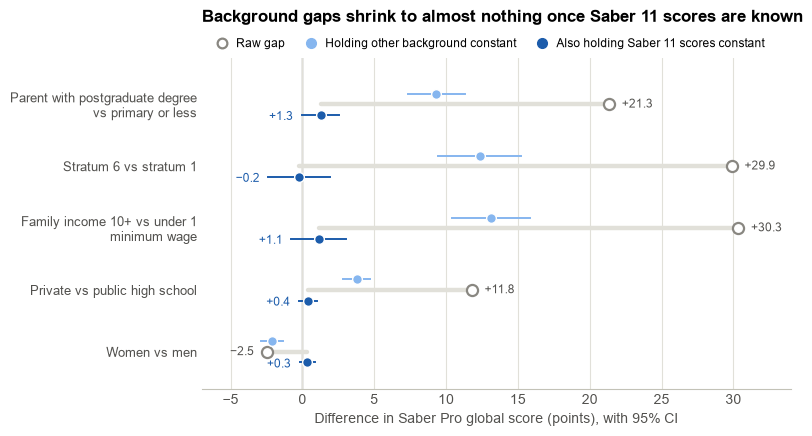

In [23]:
contrasts = [("Parent with postgraduate degree\nvs primary or less", "PAR_EDU_BAND", "PAR_EDU_BAND: Postgraduate"),
             ("Stratum 6 vs stratum 1", "STRATUM", "STRATUM: Stratum 6"),
             ("Family income 10+ vs under 1\nminimum wage", "REVENUE", "REVENUE: 10+ MMW"),
             ("Private vs public high school", "SCHOOL_NAT", "SCHOOL_NAT: Private"),
             ("Women vs men", "FEMALE", "FEMALE")]
rows = []
for label, col, term in contrasts:
    raw_table, _ = ols(cc, "G_SC", [col], {k: v for k, v in refs.items() if k == col})
    row = {"Contrast": label.replace("\n", " "), "Raw gap": raw_table.loc[term, "coef"]}
    for name, tag in [("M2", "background"), ("M3", "background + Saber 11")]:
        r = models[name][0].loc[term]
        row[f"Adjusted for {tag}"] = r["coef"]
        row[f"{tag} CI low"], row[f"{tag} CI high"] = r["95% CI low"], r["95% CI high"]
    rows.append(row)
shrink = pd.DataFrame(rows)
print("Gaps in Saber Pro global score points (same 11,695 students)")
display(shrink.round(2))
shrink.round(3).to_csv(os.path.join(OUT_DIR, "background_gaps_shrinkage.csv"), index=False)

def fig_shrinkage(shrink, title=None):
    fig, ax = plt.subplots(figsize=(7.6, 4.3))
    y = np.arange(len(shrink))
    for i, r in shrink.iterrows():
        ax.plot([r["Raw gap"], r["Adjusted for background + Saber 11"]], [i, i], color=GRID, lw=3.2,
                solid_capstyle="round", zorder=1)
        ax.plot([r["background CI low"], r["background CI high"]], [i - 0.17, i - 0.17], color=BLUE_LIGHT, lw=1.4)
        ax.plot([r["background + Saber 11 CI low"], r["background + Saber 11 CI high"]], [i + 0.17, i + 0.17],
                color=BLUE_DARK, lw=1.4)
        ax.plot(r["Raw gap"], i, "o", ms=8, mfc="white", mec=MUTED, mew=1.6, zorder=3)
        ax.plot(r["Adjusted for background"], i - 0.17, "o", ms=7, color=BLUE_LIGHT, mec="white", mew=1, zorder=3)
        ax.plot(r["Adjusted for background + Saber 11"], i + 0.17, "o", ms=7, color=BLUE_DARK, mec="white", mew=1, zorder=4)
        raw_gap = r["Raw gap"]
        ax.text(raw_gap + (0.9 if raw_gap >= 0 else -0.9), i, signed(raw_gap, 1), va="center",
                ha="left" if raw_gap >= 0 else "right", fontsize=8.5, color=INK2)
        final = r["Adjusted for background + Saber 11"]
        ax.text(min(final, r["background + Saber 11 CI low"]) - 0.6, i + 0.2, signed(final, 1), va="center",
                ha="right", fontsize=8.5, color=BLUE_DARK)
    ax.axvline(0, color=INK2, lw=0.9, zorder=0)
    ax.set_yticks(y)
    ax.set_yticklabels([c[0] for c in contrasts], fontsize=9)
    ax.set_ylim(len(shrink) - 0.4, -0.75)
    ax.set_xlim(-7, 34)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("Difference in Saber Pro global score (points), with 95% CI")
    handles = [Line2D([], [], marker="o", ls="", ms=7, mfc="white", mec=MUTED, mew=1.6, label="Raw gap"),
               Line2D([], [], marker="o", ls="", ms=7, color=BLUE_LIGHT, label="Holding other background constant"),
               Line2D([], [], marker="o", ls="", ms=7, color=BLUE_DARK, label="Also holding Saber 11 scores constant")]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5,
              handletextpad=0.2, columnspacing=1.2, borderaxespad=0.3)
    if title:
        ax.set_title(title, pad=26)
    return fig

fig = fig_shrinkage(shrink, title="Background gaps shrink to almost nothing once Saber 11 scores are known")
save(fig, "fig6_background_gaps.png")
plt.show()

**Interpretation.** Background matters a great deal for *where students start* but adds almost nothing to *where they finish* once their starting point is known.

* With other background factors held constant (M2), a postgraduate parent is still worth **9.3 points**, stratum 6 is worth **12.3 points** and the top income band is worth **13.1 points**. Together, background explains **14.7%** of the variance, and parental education alone adds 0.9 percentage points of R².
* Adding the five Saber 11 scores (M3) lifts R² to **61.5%**, and every background gap collapses to between −0.2 and +1.3 points. None of these top-category gaps is statistically different from zero. Parental education's unique contribution falls to 0.02% of the variance.
* So the influence of parental education is real and sizeable (about 21 points raw, 9 points net of other background), but it works almost entirely through the skills students bring from high school. University years carry the gap forward; they neither close it nor widen it.

## 11. Summary of findings

1. **Parental education:** yes, and substantially. There is a 20.9-point (0.95 SD) gap between students whose parents have primary schooling or less and those with a postgraduate parent, and the education of the more-educated parent explains 7.6% of the variance. First-generation students score 10.7 points lower. The effect runs through high-school achievement.
2. **Stratum:** stratum 6 performs best (181.5), and every stratum differs from every other (Tukey p < .05). Stratum explains 10% of the variance, and English is the most stratified skill (mean national percentile 50.9 in stratum 1 vs 92.5 in stratum 6).
3. **Gender:** near-parity on the global score (women 161.3, men 163.7, *d* = −0.10). Men lead in quantitative reasoning (*d* = −0.42) and women in written communication (*d* = +0.17).
4. **Other attributes:** family income (11.2% of variance), the institution's socioeconomic level (14.5%) and public vs private schooling (6.4%) follow the same socioeconomic gradient. Saber 11 results explain 61% of the variance. Chemical Engineering shows the highest value added, and students who reached Saber Pro fastest scored highest.

## 12. Targeting support and sizing the recommendations

The report recommends targeting support by measured skills rather than by family background. This section tests that choice. For each targeting rule it reports how many students the rule flags, its **precision** (the share of flagged students who finish in the bottom quarter of the global score) and its **coverage** (the share of all bottom-quarter students it flags).

It then sizes the recommendation with model M3 from section 10. Each Saber 11 point is associated with a fixed number of global-score points, holding background and the other Saber 11 subjects constant. The scenarios raise the Saber 11 English and mathematics scores of students in strata 1 and 2, capped at 100, and report the predicted change in their global scores. These are associations, not causal estimates, so they show the scale of what is at stake rather than a forecast.

In [24]:
bottom = df["G_SC_QUARTILE"] == "Q1 (lowest)"
eng_quartile = pd.qcut(df["ENG_S11"], 4, labels=False)
rules = {
    "Stratum 1 or 2": df["STRATUM_NUM"].isin([1, 2]),
    "SISBEN level 1 or 2": df["SISBEN"].isin(["Level 1", "Level 2"]),
    "First-generation student": df["FIRST_GEN"] == 1,
    "Public high school": df["SCHOOL_NAT"] == "Public",
    "Bottom quarter of Saber 11 English": eng_quartile == 0,
    "Bottom quarter of Saber 11 average": df["S11_QUARTILE"] == "Q1 (lowest)",
}
rows = []
for name, flag in rules.items():
    flag = flag.fillna(False).astype(bool)
    rows.append({"Targeting rule": name, "Students flagged": int(flag.sum()), "% of students": 100 * flag.mean(),
                 "Precision (%)": 100 * bottom[flag].mean(), "Coverage (%)": 100 * flag[bottom].mean()})
targeting = pd.DataFrame(rows).set_index("Targeting rule")
cut = df.loc[bottom, "G_SC"].max()
print(f"Bottom quarter of the global score: G_SC up to {cut:.0f} ({bottom.sum():,} students, {100 * bottom.mean():.1f}%)")
print("Table G. How well each targeting rule finds the students who finish in the bottom quarter")
display(targeting.round(1))
targeting.round(2).to_csv(os.path.join(OUT_DIR, "targeting_rules.csv"))

Bottom quarter of the global score: G_SC up to 147 (3,258 students, 26.3%)
Table G. How well each targeting rule finds the students who finish in the bottom quarter


,Students flagged,% of students,Precision (%),Coverage (%)
Targeting rule,,,,
Stratum 1 or 2,5733,46.30,35.40,62.20
SISBEN level 1 or 2,4173,33.70,39.10,50.00
First-generation student,4403,35.50,35.30,47.80
Public high school,5840,47.10,34.50,61.80
Bottom quarter of Saber 11 English,3210,25.90,57.80,56.90
Bottom quarter of Saber 11 average,3150,25.40,69.80,67.50


In [25]:
m3 = models["M3"][0]
b_eng, b_mat = m3.loc["ENG_S11", "coef"], m3.loc["MAT_S11", "coef"]
low = df["STRATUM_NUM"].isin([1, 2])
rest = df["STRATUM_NUM"].isin([3, 4, 5, 6])
gap = df.loc[rest, "G_SC"].mean() - df.loc[low, "G_SC"].mean()
print(f"Students in strata 1-2: {low.sum():,}; mean G_SC {df.loc[low, 'G_SC'].mean():.1f} vs {df.loc[rest, 'G_SC'].mean():.1f} "
      f"in strata 3-6 (gap {gap:.1f} points)")
print(f"M3 coefficients: {b_eng:.3f} global-score points per Saber 11 English point, {b_mat:.3f} per mathematics point")
print(f"Saber 11 SD: English {df['ENG_S11'].std():.1f}, mathematics {df['MAT_S11'].std():.1f}")

rows = []
target = df.loc[low]
for gain in [3, 5, 8]:
    for subject, parts in [("English", [("ENG_S11", b_eng)]), ("Mathematics", [("MAT_S11", b_mat)]),
                           ("English and mathematics", [("ENG_S11", b_eng), ("MAT_S11", b_mat)])]:
        change = sum(coef * (np.minimum(target[col] + gain, 100) - target[col]) for col, coef in parts)
        new_score = target["G_SC"] + change
        leaving = int(((target["G_SC"] <= cut) & (new_score > cut)).sum())
        rows.append({"Saber 11 gain (points)": gain, "Subject": subject,
                     "Predicted G_SC gain": change.mean(), "% of gap to strata 3-6 closed": 100 * change.mean() / gap,
                     "Students leaving the bottom quarter": leaving})
sizing = pd.DataFrame(rows)
print("\nTable H. Predicted effect of higher Saber 11 scores for students in strata 1 and 2 (model M3)")
display(sizing.round(2))
sizing.round(3).to_csv(os.path.join(OUT_DIR, "recommendation_sizing.csv"), index=False)
print(f"Students in strata 1-2 now in the bottom quarter: {int((low & bottom).sum()):,}")

Students in strata 1-2: 5,733; mean G_SC 156.5 vs 168.1 in strata 3-6 (gap 11.7 points)
M3 coefficients: 0.454 global-score points per Saber 11 English point, 0.294 per mathematics point
Saber 11 SD: English 14.3, mathematics 11.9

Table H. Predicted effect of higher Saber 11 scores for students in strata 1 and 2 (model M3)


,Saber 11 gain (points),Subject,Predicted G_SC gain,% of gap to strata 3-6 closed,Students leaving the bottom quarter
0,3,English,1.36,11.67,204
1,3,Mathematics,0.88,7.54,108
2,3,English and mathematics,2.24,19.22,293
3,5,English,2.27,19.45,293
4,5,Mathematics,1.46,12.56,204
5,5,English and mathematics,3.73,32.01,388
6,8,English,3.62,31.08,388
7,8,Mathematics,2.33,20.04,293
8,8,English and mathematics,5.96,51.11,557


Students in strata 1-2 now in the bottom quarter: 2,027


In [26]:
print("Figures saved for the report:")
for name in sorted(os.listdir(FIG_DIR)):
    print("  ", os.path.join(FIG_DIR, name))
print("Tables saved:")
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", os.path.join(OUT_DIR, name))

Figures saved for the report:
   figures/fig1_parent_education.png
   figures/fig2_stratum.png
   figures/fig3_modules_by_stratum.png
   figures/fig4_gender_gaps.png
   figures/fig5_variance_explained.png
   figures/fig6_background_gaps.png
Tables saved:
   outputs/background_gaps_shrinkage.csv
   outputs/gender_gaps_by_subject.csv
   outputs/gsc_by_gender.csv
   outputs/gsc_by_parent_education.csv
   outputs/gsc_by_stratum.csv
   outputs/numeric_summary.csv
   outputs/programs.csv
   outputs/recommendation_sizing.csv
   outputs/regression_models.csv
   outputs/targeting_rules.csv
   outputs/variance_explained_by_attribute.csv
